## Imports

In [1]:
import os
import warnings
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
from itertools import combinations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import subprocess
from scipy.optimize import least_squares
from scipy import stats

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from Bio.SeqIO import parse
from Bio import SeqIO
from Bio import Phylo

from typing import Tuple, Optional, List

import gffutils
import baltic as bt

# Utils

## Distances

In [2]:
def hamming_distance(s1, s2):
    if len(s1) != len(s2):
        raise ValueError("Strings must be of the same length")
    
    return sum(el1 != el2 for el1, el2 in zip(s1, s2))

In [3]:
def grantham_distance(s1, s2):
    grantham_matrix = {
      'A': {'A':0,'R':112,'N':111,'D':126,'C':195,'Q':91,'E':107,'G':60,'H':86,'I':94,'L':96,'K':106,'M':84,'F':113,'P':27,'S':99,'T':58,'W':148,'Y':112,'V':64},
      'R': {'A':112,'R':0,'N':86,'D':96,'C':180,'Q':43,'E':54,'G':125,'H':29,'I':97,'L':102,'K':26,'M':91,'F':97,'P':103,'S':110,'T':71,'W':101,'Y':77,'V':96},
      'N': {'A':111,'R':86,'N':0,'D':23,'C':139,'Q':46,'E':42,'G':80,'H':68,'I':149,'L':153,'K':94,'M':142,'F':158,'P':91,'S':46,'T':65,'W':174,'Y':143,'V':133},
      'D': {'A':126,'R':96,'N':23,'D':0,'C':154,'Q':61,'E':45,'G':94,'H':81,'I':168,'L':172,'K':101,'M':160,'F':177,'P':108,'S':65,'T':85,'W':181,'Y':160,'V':152},
      'C': {'A':195,'R':180,'N':139,'D':154,'C':0,'Q':154,'E':170,'G':159,'H':174,'I':198,'L':198,'K':202,'M':196,'F':205,'P':169,'S':112,'T':149,'W':215,'Y':194,'V':192},
      'Q': {'A':91,'R':43,'N':46,'D':61,'C':154,'Q':0,'E':29,'G':87,'H':24,'I':109,'L':113,'K':53,'M':101,'F':116,'P':76,'S':68,'T':42,'W':130,'Y':99,'V':96},
      'E': {'A':107,'R':54,'N':42,'D':45,'C':170,'Q':29,'E':0,'G':98,'H':40,'I':134,'L':138,'K':56,'M':126,'F':140,'P':93,'S':80,'T':65,'W':152,'Y':122,'V':121},
      'G': {'A':60,'R':125,'N':80,'D':94,'C':159,'Q':87,'E':98,'G':0,'H':98,'I':135,'L':138,'K':127,'M':127,'F':153,'P':42,'S':56,'T':59,'W':184,'Y':147,'V':109},
      'H': {'A':86,'R':29,'N':68,'D':81,'C':174,'Q':24,'E':40,'G':98,'H':0,'I':94,'L':99,'K':32,'M':87,'F':100,'P':77,'S':89,'T':47,'W':115,'Y':83,'V':84},
      'I': {'A':94,'R':97,'N':149,'D':168,'C':198,'Q':109,'E':134,'G':135,'H':94,'I':0,'L':5,'K':102,'M':10,'F':21,'P':95,'S':142,'T':89,'W':61,'Y':33,'V':29},
      'L': {'A':96,'R':102,'N':153,'D':172,'C':198,'Q':113,'E':138,'G':138,'H':99,'I':5,'L':0,'K':107,'M':15,'F':22,'P':98,'S':145,'T':92,'W':61,'Y':36,'V':32},
      'K': {'A':106,'R':26,'N':94,'D':101,'C':202,'Q':53,'E':56,'G':127,'H':32,'I':102,'L':107,'K':0,'M':95,'F':102,'P':103,'S':121,'T':78,'W':110,'Y':85,'V':97},
      'M': {'A':84,'R':91,'N':142,'D':160,'C':196,'Q':101,'E':126,'G':127,'H':87,'I':10,'L':15,'K':95,'M':0,'F':28,'P':87,'S':135,'T':81,'W':67,'Y':36,'V':21},
      'F': {'A':113,'R':97,'N':158,'D':177,'C':205,'Q':116,'E':140,'G':153,'H':100,'I':21,'L':22,'K':102,'M':28,'F':0,'P':114,'S':155,'T':103,'W':40,'Y':22,'V':50},
      'P': {'A':27,'R':103,'N':91,'D':108,'C':169,'Q':76,'E':93,'G':42,'H':77,'I':95,'L':98,'K':103,'M':87,'F':114,'P':0,'S':74,'T':38,'W':147,'Y':110,'V':68},
      'S': {'A':99,'R':110,'N':46,'D':65,'C':112,'Q':68,'E':80,'G':56,'H':89,'I':142,'L':145,'K':121,'M':135,'F':155,'P':74,'S':0,'T':58,'W':177,'Y':144,'V':124},
      'T': {'A':58,'R':71,'N':65,'D':85,'C':149,'Q':42,'E':65,'G':59,'H':47,'I':89,'L':92,'K':78,'M':81,'F':103,'P':38,'S':58,'T':0,'W':128,'Y':92,'V':69},
      'W': {'A':148,'R':101,'N':174,'D':181,'C':215,'Q':130,'E':152,'G':184,'H':115,'I':61,'L':61,'K':110,'M':67,'F':40,'P':147,'S':177,'T':128,'W':0,'Y':37,'V':88},
      'Y': {'A':112,'R':77,'N':143,'D':160,'C':194,'Q':99,'E':122,'G':147,'H':83,'I':33,'L':36,'K':85,'M':36,'F':22,'P':110,'S':144,'T':92,'W':37,'Y':0,'V':55},
      'V': {'A':64,'R':96,'N':133,'D':152,'C':192,'Q':96,'E':121,'G':109,'H':84,'I':29,'L':32,'K':97,'M':21,'F':50,'P':68,'S':124,'T':69,'W':88,'Y':55,'V':0}
   }
    
    if len(s1) != len(s2):
        raise ValueError("Sequences must be of the same length")

    distance = 0

    for aa1, aa2 in zip(s1, s2):
        if aa1 == "-" or aa2 == "-":
            continue
        if aa1 == "*" or aa2 == "*":
            continue
        if aa1 not in grantham_matrix or aa2 not in grantham_matrix[aa1]:
            continue
        distance += grantham_matrix[aa1][aa2]
    return distance

In [4]:
def antigenic_distance(s1, s2, sero, type='grantham'):

    # Posiciones en numeración 1-based (convención de la literatura)
    locations_EDI = [
        [47, 47], [123, 126], [148, 165], [167, 167],
        [170, 177], [180, 180], [279, 279], [293, 293]
    ]
    locations_EDII = [
        [67, 74], [76, 79], [88, 88], [97, 118],
        [215, 215], [219, 219], [233, 233], [237, 237],
        [244, 249], [256, 256], [266, 268], [272, 276]
    ]
    locations_EDIII = [
        [282, 282], [298, 311], [314, 370],
        [372, 372], [382, 385], [387, 390]
    ]

    # DENV3 E protein is 2 residues shorter due to a deletion at
    # positions 158-159 (relative to DENV1/2/4 numbering).
    # Every position > 159 is shifted by -2 (still 1-based).
    sero_id = str(sero).upper()
    if sero == 3 or '3' in sero_id:
        def _shift(loc):
            s, e = loc
            if s > 159:
                return [s - 2, e - 2]
            elif e > 159:
                # Region spans the deletion boundary
                return [s, e - 2]
            return [s, e]

        locations_EDI   = [_shift(l) for l in locations_EDI]
        locations_EDII  = [_shift(l) for l in locations_EDII]
        locations_EDIII = [_shift(l) for l in locations_EDIII]

    def _domain_distance(locations):
        total_dist = 0
        n_residues = 0
        for start, end in locations:
            # Conversión de 1-based inclusivo a slicing 0-based: [start-1 : end]
            if type == 'grantham':
                total_dist += grantham_distance(s1[start - 1:end],s2[start - 1:end])
            else:
                total_dist += hamming_distance(s1[start - 1:end],s2[start - 1:end])
            n_residues += end - start + 1
        return total_dist, n_residues

    sum_dist_EDI,   n_EDI   = _domain_distance(locations_EDI)
    sum_dist_EDII,  n_EDII  = _domain_distance(locations_EDII)
    sum_dist_EDIII, n_EDIII = _domain_distance(locations_EDIII)

    w = 215 if type == 'grantham' else 1

    total_sum = sum_dist_EDI + sum_dist_EDII + sum_dist_EDIII
    total_n   = n_EDI + n_EDII + n_EDIII

    if total_n == 0:
        return 0.0

    epit_dist = (total_sum / (total_n * w)) * 10
    return epit_dist

## Others

### Load or Create DB

In [5]:
folder_path = "../output/db"
os.makedirs(folder_path, exist_ok=True)

def load_or_create_db(gff_path, db_name):
    if not os.path.exists(db_name):
        print(f"Creating {db_name}...")
        gffutils.create_db(
            gff_path,
            dbfn=db_name,
            force=True,
            keep_order=True,
            merge_strategy="merge",
            sort_attribute_values=True
        )
    else:
        print(f"{db_name} already exists. Loading...")

    return gffutils.FeatureDB(db_name)


db_denv1 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV1.gff3", "../output/db/denv1.db")
db_denv2 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV2.gff3", "../output/db/denv2.db")
db_denv3 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV3.gff3", "../output/db/denv3.db")
db_denv4 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV4.gff3", "../output/db/denv4.db")


../output/db/denv1.db already exists. Loading...
../output/db/denv2.db already exists. Loading...
../output/db/denv3.db already exists. Loading...
../output/db/denv4.db already exists. Loading...


### Get Feature Coords

In [6]:
def get_feature_coords(db, feature_name):
    for f in db.features_of_type("mature_protein_region_of_CDS"):
        product_name = f.attributes.get("product", [""])[0]
        if feature_name in product_name:
            return f.start, f.end, f.strand
    return None

## Augur Functions

In [26]:
def augur_align(in_seqs=None, ref_seq=None, out_aln=None, fill_gaps=False, nthreads="auto"):
    cmd = [
        "augur", "align",
        "--sequences", in_seqs,
        "--output", out_aln,
        "--nthreads", str(nthreads)
    ]
    if ref_seq:
        cmd.extend(["--reference-sequence", ref_seq])
    if fill_gaps:
        cmd.append("--fill-gaps")
    subprocess.run(cmd, check=True)

In [27]:
def augur_tree(in_seqs=None, method="iqtree", sub_model="GTR+G", nthreads="auto", out_tree=None):
    subprocess.run([
            "augur", "tree",
            "--alignment", in_seqs,
            "--method", method,
            "--substitution-model", sub_model,
            "--nthreads", nthreads,
            "--output", out_tree
        ], check=True)

In [28]:
def augur_refine(in_tree=None, in_seqs=None, in_meta=None, clock="4", out_tree=None, out_node=None):
    subprocess.run([
            "augur", "refine",
            "--tree", in_tree,
            "--alignment", in_seqs,
            "--metadata", in_meta,
            "--timetree",
            "--clock-filter-iqd", clock,
            "--output-tree", out_tree,
            "--output-node-data", out_node,
            "--stochastic-resolve"
        ], check=True)

In [29]:
def augur_ancestral(in_tree=None, in_seqs=None, out_node=None, out_seqs=None):
    subprocess.run([
        "augur", "ancestral",
        "--tree", in_tree,
        "--alignment", in_seqs,
        "--output-node-data", out_node,
        "--output-sequences", out_seqs
    ], check=True)

In [30]:
def augur_translate(in_tree=None, ancestral_seqs=None, ref_seq=None, genes=None, out_node=None, out_aln=None):
    cmd = [
        "augur", "translate",
        "--tree", in_tree,
        "--ancestral-sequences", ancestral_seqs,
        "--reference-sequence", ref_seq,
        "--output-node-data", out_node,
        "--alignment-output", out_aln
    ]
    if genes:
        cmd.append("--genes")
        cmd.extend(genes if isinstance(genes, list) else [genes])
    subprocess.run(cmd, check=True)

# Paths

## Reference Paths

In [5]:
REF_SEQ = "../resources/reference_data/sequences/ref_DENV{}.fasta"
CROP_REF_SEQS = "../resources/reference_data/cropped/ref_DENV{}.fasta"
AA_REF_SEQ = "../resources/reference_data/AA_sequences/ref_DENV{}.fasta"

## Colombia Paths

In [6]:
IN_SEQS_COL = "../resources/colombia_data/sequences/col_DENV{}.fasta"
ALN_SEQS_COL = "../resources/colombia_data/aligned/align_DENV{}.fasta"
CROP_SEQS_COL = "../resources/colombia_data/cropped/align_DENV{}.fasta"
META_COL = "../resources/colombia_data/metadata/col_DENV{}_meta.tsv"
META_CLEAN_COL = "../resources/colombia_data/metadata/E_DENV{}_meta.tsv"
TMP_GFF_COL = "../resources/colombia_data/tmp/E_DENV{}.gff"
TREE_COL = "../resources/colombia_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_COL = "../resources/colombia_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_COL = "../resources/colombia_data/refined/E_DENV{}_tree_node.json"
NODE_AA_COL="../resources/colombia_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_COL="../resources/colombia_data/AA_sequences/E_DENV{}_aa_%GENE.fasta"
AA_SEQS_COL_E="../resources/colombia_data/AA_sequences/E_DENV{}_aa_E.fasta"
ANCESTRAL_NODE_COL="../resources/colombia_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_COL="../resources/colombia_data/ancestral/E_DENV{}_ancestral.fasta"
TIP_DATES_COL= "../resources/colombia_data/dates/DENV{}_dates_beauti.txt"

all_paths = [
    IN_SEQS_COL, ALN_SEQS_COL, CROP_SEQS_COL, META_COL, META_CLEAN_COL, 
    TMP_GFF_COL, TREE_COL, TIME_TREE_COL, NODE_TREE_COL, NODE_AA_COL, 
    AA_SEQS_COL, AA_SEQS_COL_E, ANCESTRAL_NODE_COL, ANCESTRAL_SEQS_COL
]

for file_path in all_paths:
    dir_path = Path(file_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)

## Experimental Paths

In [7]:
IN_COMB_EXP = "../resources/experimental_data/sequences/full-genome-only-sequences.fasta"
IN_SEQS_EXP = "../resources/experimental_data/sequences/col_DENV{}.fasta"
ALN_SEQS_EXP = "../resources/experimental_data/aligned/align_DENV{}.fasta"
CROP_SEQS_EXP = "../resources/experimental_data/cropped/E_DENV{}.fasta"
META_EXP = "../resources/experimental_data/metadata/E_DENV{}_meta.tsv"
TMP_GFF_EXP = "../resources/experimental_data/tmp/E_DENV{}.gff"
TREE_EXP = "../resources/experimental_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_EXP = "../resources/experimental_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_EXP = "../resources/experimental_data/refined/E_DENV{}_tree_node.json"
NODE_AA_EXP="../resources/experimental_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_EXP="../resources/experimental_data/AA_sequences/E_DENV{}_aa_%GENE.fasta"
AA_SEQS_EXP_E="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E.fasta"
ANCESTRAL_NODE_EXP="../resources/experimental_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_EXP="../resources/experimental_data/ancestral/E_DENV{}_ancestral.fasta"
AA_SEQS_EXP_E_map="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"

all_paths = [
    IN_COMB_EXP, IN_SEQS_EXP, ALN_SEQS_EXP, CROP_SEQS_EXP, META_EXP, 
    TMP_GFF_EXP, TREE_EXP, TIME_TREE_EXP, NODE_TREE_EXP, NODE_AA_EXP, 
    AA_SEQS_EXP, AA_SEQS_EXP_E, ANCESTRAL_NODE_EXP, ANCESTRAL_SEQS_EXP
]

for file_path in all_paths:
    dir_path = Path(file_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)

## Merged Paths

In [8]:
CROP_SEQS_MERGE = "../resources/merged_data/cropped/align_DENV{}.fasta"
META_MERGE = "../resources/merged_data/metadata/merged_DENV{}_meta.tsv"
TMP_GFF_MERGE = "../resources/merged_data/tmp/E_DENV{}.gff"
TREE_MERGE = "../resources/merged_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_node.json"
NODE_AA_MERGE="../resources/merged_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_MERGE="../resources/merged_data/AA_sequences/E_DENV{}_aa_%GENE.fasta"
AA_SEQS_MERGE_E="../resources/merged_data/AA_sequences/E_DENV{}_aa_E.fasta"
ANCESTRAL_NODE_MERGE="../resources/merged_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_MERGE="../resources/merged_data/ancestral/E_DENV{}_ancestral.fasta"

path_templates = [
    CROP_SEQS_MERGE, META_MERGE,
    TMP_GFF_MERGE, TREE_MERGE, TIME_TREE_MERGE, NODE_TREE_MERGE,
    NODE_AA_MERGE, AA_SEQS_MERGE, AA_SEQS_MERGE_E,
    ANCESTRAL_NODE_MERGE, ANCESTRAL_SEQS_MERGE
]

created_dirs = set()
for template in path_templates:
    dir_path = Path(template).parent
    if dir_path not in created_dirs:
        dir_path.mkdir(parents=True, exist_ok=True)
        created_dirs.add(dir_path)

# Prepare Reference Data

In [42]:
dbs = {1: db_denv1, 2: db_denv2, 3: db_denv3, 4: db_denv4}
feature_name = "envelope protein E"

for sero in range(1, 5):
    db = dbs[sero]
    ref_in = REF_SEQ.format(sero)
    crop_out = CROP_REF_SEQS.format(sero)
    aa_out = AA_REF_SEQ.format(sero)

    print(f"\nProcessing DENV{sero}...")

    coords = get_feature_coords(db, feature_name)
    if not coords:
        print(f"  Skipped: '{feature_name}' not found in DENV{sero} DB.")
        continue
    start, end, strand = coords
    print(f"  Found E region: {start}-{end}")

    if not os.path.exists(ref_in):
        raise FileNotFoundError(f"Reference FASTA not found: {ref_in}")
    ref_record = SeqIO.read(ref_in, "fasta")
    ref_seq = ref_record.seq

    cds_seq = ref_seq[start-1:end]

    with open(crop_out, "w") as f:
        f.write(f">{ref_record.id}_E_CDS\n")
        f.write(str(cds_seq) + "\n")
    print(f"  Saved nucleotide: {crop_out}")

    if len(cds_seq) % 3 != 0:
        print(f"  Warning: CDS length ({len(cds_seq)}) not multiple of 3. Padding with N...")
        cds_seq += Seq("N" * (3 - len(cds_seq) % 3))

    aa_seq = cds_seq.translate(table=1, to_stop=False)
    if str(aa_seq).endswith("*"):
        aa_seq = aa_seq[:-1]

    with open(aa_out, "w") as f:
        f.write(f">{ref_record.id}_E_protein\n")
        seq_str = str(aa_seq)
        for i in range(0, len(seq_str), 80):
            f.write(seq_str[i:i+80] + "\n")
    print(f"  Saved AA: {aa_out} ({len(aa_seq)} amino acids)")


Processing DENV1...
  Found E region: 935-2419
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV1.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV1.fasta (495 amino acids)

Processing DENV2...
  Found E region: 937-2421
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV2.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV2.fasta (495 amino acids)

Processing DENV3...
  Found E region: 935-2413
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV3.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV3.fasta (493 amino acids)

Processing DENV4...
  Found E region: 939-2423
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV4.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV4.fasta (495 amino acids)


# Colombia Data

## Align sequences

In [ ]:
for i in range(4):
    print(f"Aligning DENV{i+1}")
    serotype = i + 1
    augur_align(
        in_seqs=IN_SEQS_COL.format(serotype),
        ref_seq=REF_SEQ.format(serotype),
        out_aln=ALN_SEQS_COL.format(serotype),
        fill_gaps=True,
        nthreads="auto"
    )

## Crop alignments gene E

In [15]:
for i in range(4):
    print(f"Crop DENV{i+1}")
    serotype = i + 1
    db = [db_denv1, db_denv2, db_denv3, db_denv4][i]
    e_start, e_end, strand = get_feature_coords(db, "envelope protein E")
    cropped_records = []
    
    for j, record in enumerate(SeqIO.parse(ALN_SEQS_COL.format(serotype), "fasta")):
        
        if j == 0:
            continue
            
        if len(record.seq) < e_end:
            continue
        
        cropped_seq = record.seq[e_start-1:e_end]
        
        record.seq = cropped_seq

        new_id = record.id.split("|")[0]
        
        record.id = new_id
        record.name = new_id
        record.description = new_id
        
        cropped_records.append(record)
    
    SeqIO.write(
        cropped_records,
        CROP_SEQS_COL.format(serotype),
        "fasta"
    )


Crop DENV1
Crop DENV2
Crop DENV3
Crop DENV4


## Create Tip dates for BEAST

In [16]:
def extract_date_from_header(header):
    parts = header.split('|')
    if len(parts) < 2:
        return None
    
    date_str = parts[-1].strip()
    
    try:
        if len(date_str) == 10:
            d = datetime.strptime(date_str, "%Y-%m-%d")
            return d.year + (d.timetuple().tm_yday - 1) / 365.0
        elif len(date_str) == 7:
            year, month = map(int, date_str.split('-'))
            return year + ((month - 1) / 12.0) + (15 / 365.0)
        elif len(date_str) == 4:
            return float(date_str) + 0.5
    except:
        pass
    return None

for i in range(4):
    in_path = ALN_SEQS_COL.format(i+1)
    out_path = TIP_DATES_COL.format(i+1)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with open(in_path.format(i+1), 'r') as f_in, open(out_path.format(i+1), 'w') as f_out:
        for line in f_in:
            if line.startswith('>'):
                full_header = line[1:].strip()
                date_decimal = extract_date_from_header(full_header)
                if date_decimal is not None:
                    seq_id = full_header.split('|')[0]
                    f_out.write(f"{seq_id}\t{date_decimal:.4f}\n")
    
    print(f"Archivo generado: {out_path.format(i+1)}")

Archivo generado: ../resources/colombia_data/dates/DENV1_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV2_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV3_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV4_dates_beauti.txt


## Clean Metadata

In [8]:
for i in range(4):
    print(f"Clean Metadata DENV{i+1}")
    serotype = i + 1
    
    df = pd.read_csv(META_COL.format(serotype), sep="\t")
    
    df = df.rename(columns={
        "Virus name": "strain",
        "Collection date": "date",
        "Location": "location",
        "Genotype": "genotype",
        "Lineage": "lineage",
    })
    
    location_split = df["location"].str.split(" / ", expand=True)
    
    df["region"] = location_split[0]
    df["country"] = location_split[1]
    df["division"] = location_split[2]
    
    metadata = df[["strain", "date", "region", "country", "division", "genotype", "lineage"]]
   
    metadata.to_csv(META_CLEAN_COL.format(serotype), sep="\t", index=False)

Clean Metadata DENV1
Clean Metadata DENV2
Clean Metadata DENV3
Clean Metadata DENV4


## Create temp GFF

In [17]:
for i in range(4):
    print(f"Create temporal GFF DENV{i+1}")
    serotype = i + 1
    
    first_record = next(SeqIO.parse(CROP_SEQS_COL.format(serotype), "fasta"))
    gene_length = len(first_record.seq)
    seqid = first_record.id
    
    with open(TMP_GFF_COL.format(serotype), "w") as gff:
        gff.write("##gff-version 3\n")
        
        gff.write(
            f"{seqid}\t.\tsource\t1\t{gene_length}\t.\t+\t.\tID=nuc\n"
        )
        
        gff.write(
            f"{seqid}\t.\tgene\t1\t{gene_length}\t.\t+\t.\tID=E;Name=E;gene=E\n"
        )


Create temporal GFF DENV1
Create temporal GFF DENV2
Create temporal GFF DENV3
Create temporal GFF DENV4


## Tree Augur Workflow

In [20]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_COL.format(serotype),
               out_tree=TREE_COL.format(serotype))
    
    augur_refine(in_tree=TREE_COL.format(serotype),
                 in_seqs=CROP_SEQS_COL.format(serotype),
                 in_meta=META_CLEAN_COL.format(serotype),
                 out_tree=TIME_TREE_COL.format(serotype),
                 out_node=NODE_TREE_COL.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_COL.format(serotype),
        in_seqs=CROP_SEQS_COL.format(serotype),
        out_node=ANCESTRAL_NODE_COL.format(serotype),
        out_seqs=ANCESTRAL_SEQS_COL.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 48.85166072845459 seconds
augur refine is using TreeTime version 0.11.4

0.17	TreeTime.reroot: with method or node: least-squares

0.17	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.31	TreeTime.reroot: with method or node: least-squares

0.31	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.
pruning leaf  hDenV1/Colombia/BOL-UEB-016/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-016-1/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152-1/2019

0.92	TreeTime.reroot: with method or node: least-squares

0.92	TreeTime.rer

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.610790967941284 seconds
augur refine is using TreeTime version 0.11.4

0.22	TreeTime.reroot: with method or node: least-squares

0.22	TreeTime.reroot: rerooting wi

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 44.474406003952026 seconds
augur refine is using TreeTime version 0.11.4

0.14	TreeTime.reroot: with method or node: least-squares

0.14	TreeTime.reroot: rerooting wi

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 49.11110305786133 seconds
augur refine is using TreeTime version 0.11.4

0.02	TreeTime.reroot: with method or node: least-squares

0.02	TreeTime.reroot: rerooting wil

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV4_ancestral.json'...


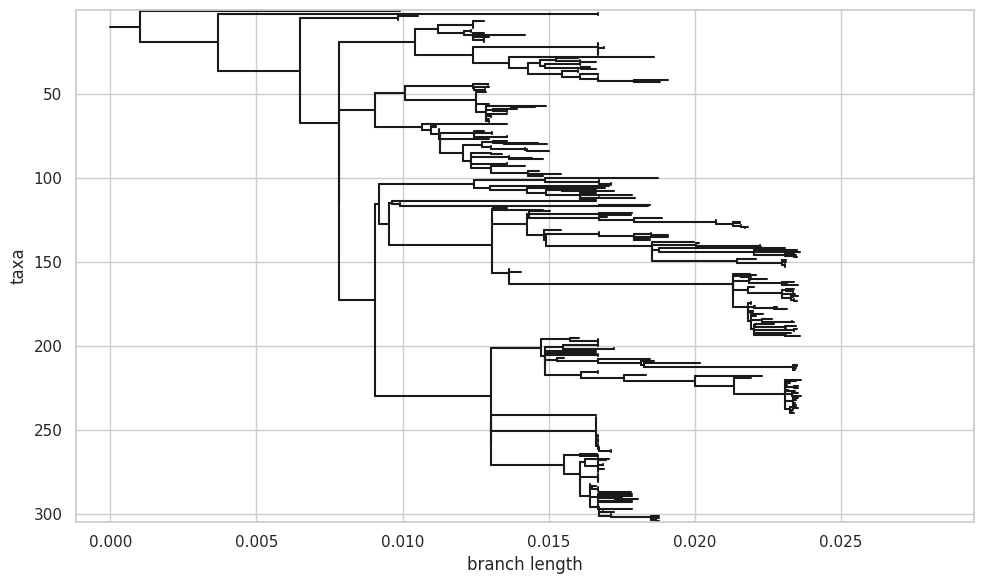

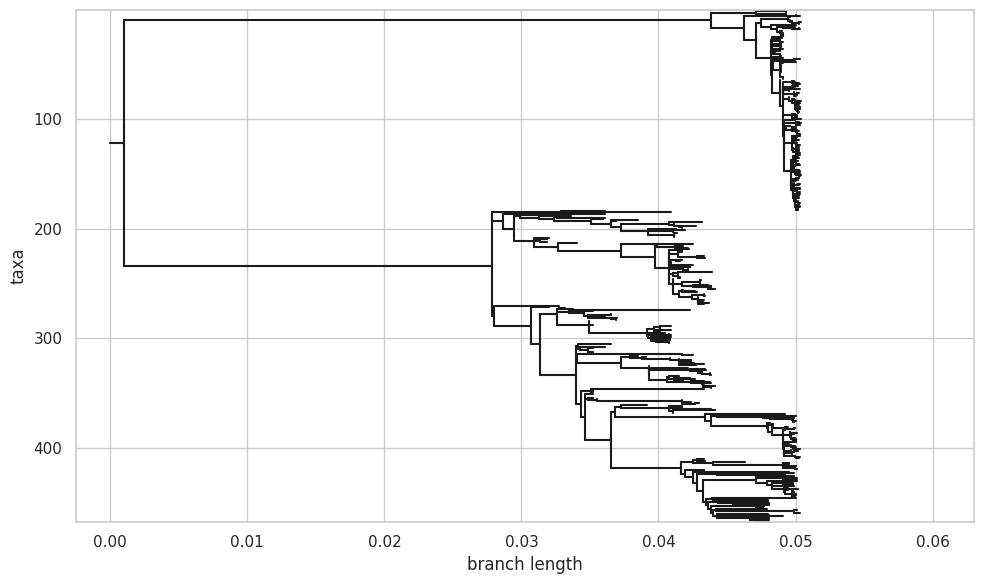

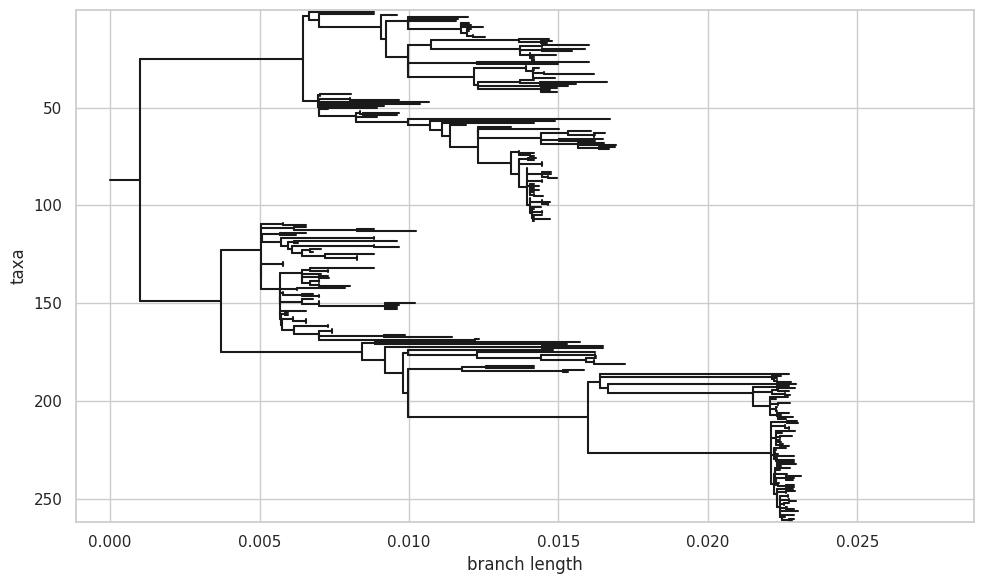

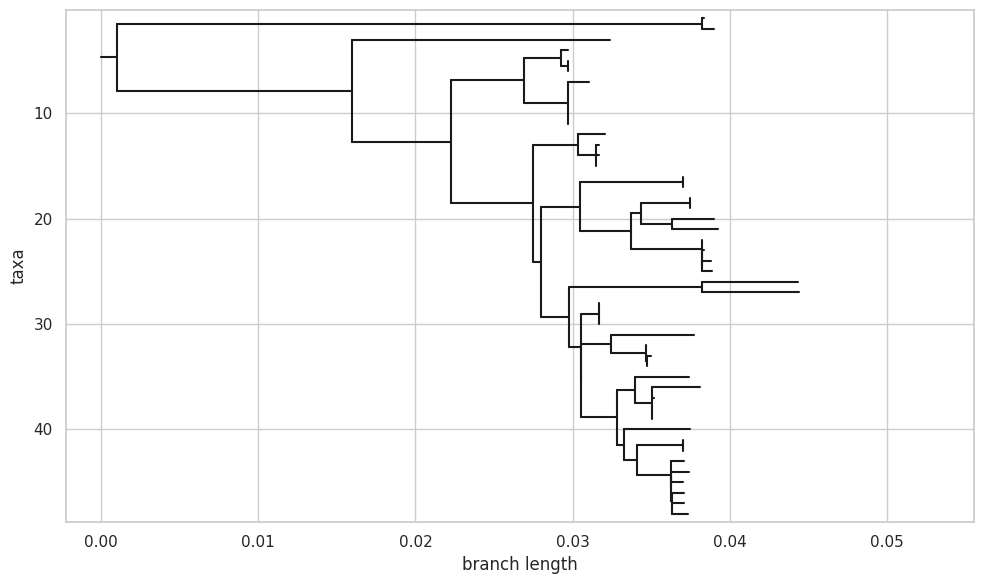

In [21]:
for i in range(4):
    sero = i+1
    tree = Phylo.read(TIME_TREE_COL.format(sero), "newick")
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    Phylo.draw(
        tree,
        axes=ax,
        label_func=lambda x: None,
        branch_labels=False,
        do_show=False
    )
    
    plt.tight_layout()
    #plt.savefig("phylogenetic_tree.png", dpi=300)
    plt.show()

## Transtale from refined tree using Augur

In [22]:
for i in range(4):
    sero = i+1
    print(f"Translating DENV{sero}")
    
    augur_translate(
        in_tree=TIME_TREE_COL.format(sero),
        ancestral_seqs=ANCESTRAL_NODE_COL.format(sero),
        ref_seq=TMP_GFF_COL.format(serotype),
        genes=["E"],
        out_node=NODE_AA_COL.format(sero),
        out_aln=AA_SEQS_COL.format(sero)
    )

Translating DENV1


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV1_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV1_aa.json


Translating DENV2


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV2_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV2_aa.json


Translating DENV3


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV3_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV3_aa.json


Translating DENV4


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV4_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV4_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV4_aa.json


## Sequence Count

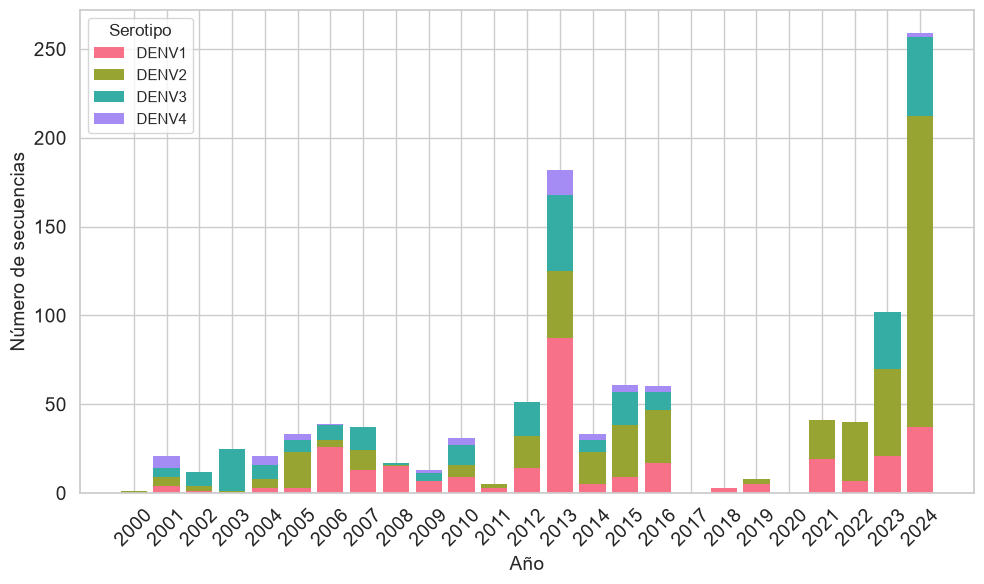

In [9]:
plot_data = []
all_years = None

for i in range(4):
    sero = i+1
    
    df = pd.read_csv(META_CLEAN_COL.format(sero), sep="\t")
    df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
    df = df.dropna(subset=["date"])
    df["year"] = df["date"].dt.year
    
    counts = df.groupby("year").size()

    if all_years is None:
        all_years = range(counts.index.min(), counts.index.max() + 1)
    else:
        all_years = range(min(all_years[0], counts.index.min()), 
                         max(all_years[-1], counts.index.max()) + 1)
    

    counts = counts.reindex(all_years, fill_value=0).reset_index()
    counts.columns = ["year", "count"]
    counts["serotype"] = f"DENV{sero}"
    plot_data.append(counts)

plot_df = pd.concat(plot_data, ignore_index=True)

plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)

plt.figure(figsize=(10, 6))

colors = sns.color_palette("husl", n_colors=len(plot_pivot.columns))

bottom = np.zeros(len(plot_pivot))

for serotype, color in zip(plot_pivot.columns, colors):
    plt.bar(
        plot_pivot.index,
        plot_pivot[serotype],
        bottom=bottom,
        label=serotype,
        color=color,
        linewidth=0
    )
    bottom += plot_pivot[serotype].values

plt.xlabel("Año", fontsize=14)
plt.ylabel("Número de secuencias", fontsize=14)
'''
plt.title(
    "Distribución temporal de las secuencias de Colombia del gen E",
    fontsize=14,
    fontweight="bold"
)
'''
plt.legend(title="Serotipo")
plt.xticks(plot_pivot.index, rotation=45, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig("../figures/distribucion_temporal_colombia.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [10]:
total_by_year = (
    plot_df
    .groupby("year", as_index=False)["count"]
    .sum()
    .rename(columns={"count": "total_sequences"})
)

total_by_year

,year,total_sequences
0,2000,1
1,2001,21
2,2002,12
3,2003,25
4,2004,21
5,2005,33
6,2006,39
7,2007,37
8,2008,17
9,2009,13


# Experimental (Antigenic Map) Data

## Split Original FASTA

In [51]:
out_handles = {i: open(IN_SEQS_EXP.format(i), "w") for i in range(1, 5)}

try:
    for record in SeqIO.parse(IN_COMB_EXP, "fasta"):
        sero_name = record.id.split("/")[0]
        
        if sero_name.startswith("DENV"):
            try:
                sero_num = int(sero_name.replace("DENV", ""))
                if sero_num in out_handles:
                    record.description = "" 
                    SeqIO.write(record, out_handles[sero_num], "fasta")
            except ValueError:
                print(f"  Warning: Could not parse serotype number from {record.id}")
finally:
    for h in out_handles.values():
        h.close()
        
print("  Finished splitting FASTA files.\n")

  Finished splitting FASTA files.



## Align sequences

In [52]:
for i in range(4):
    print(f"Aligning DENV{i+1}")
    serotype = i + 1
    augur_align(
        in_seqs=IN_SEQS_EXP.format(serotype),
        ref_seq=REF_SEQ.format(serotype),
        out_aln=ALN_SEQS_EXP.format(serotype),
        fill_gaps=True,
        nthreads="auto"
    )

Aligning DENV1

using mafft to align via:
	mafft --reorder --anysymbol --nomemsave --adjustdirection --thread 16 ../resources/experimental_data/aligned/align_DENV1.fasta.to_align.fasta 1> ../resources/experimental_data/aligned/align_DENV1.fasta 2> ../resources/experimental_data/aligned/align_DENV1.fasta.log 

	Katoh et al, Nucleic Acid Research, vol 30, issue 14
	https://doi.org/10.1093%2Fnar%2Fgkf436

No gaps in alignment to trim (with respect to the reference, NC_001477.1)
Aligning DENV2

using mafft to align via:
	mafft --reorder --anysymbol --nomemsave --adjustdirection --thread 16 ../resources/experimental_data/aligned/align_DENV2.fasta.to_align.fasta 1> ../resources/experimental_data/aligned/align_DENV2.fasta 2> ../resources/experimental_data/aligned/align_DENV2.fasta.log 

	Katoh et al, Nucleic Acid Research, vol 30, issue 14
	https://doi.org/10.1093%2Fnar%2Fgkf436

No gaps in alignment to trim (with respect to the reference, NC_001474.2)
Aligning DENV3

using mafft to align via

## Crop Aligments Gen E

In [53]:
for i in range(4):
    print(f"Crop DENV{i+1}")
    serotype = i + 1
    db = [db_denv1, db_denv2, db_denv3, db_denv4][i]
    e_start, e_end, strand = get_feature_coords(db, "envelope protein E")
    cropped_records = []
    
    for j, record in enumerate(SeqIO.parse(ALN_SEQS_EXP.format(serotype), "fasta")):
        
        if j == 0:
            continue
            
        if len(record.seq) < e_end:
            continue
        
        cropped_seq = record.seq[e_start-1:e_end]
        
        record.seq = cropped_seq

        new_id = record.id.split("|")[0]
        
        record.id = new_id
        record.name = new_id
        record.description = new_id
        
        cropped_records.append(record)
    
    SeqIO.write(
        cropped_records,
        CROP_SEQS_EXP.format(serotype),
        "fasta"
    )


Crop DENV1
Crop DENV2
Crop DENV3
Crop DENV4


## Create Metadata

In [54]:
for i in range(4):
    sero_num = i + 1
    crop_fasta = CROP_SEQS_EXP.format(sero_num)
    meta_path = META_EXP.format(sero_num)

    print(f"Step 2: Processing DENV{sero_num} Metadata")

    meta_rows = []

    for record in SeqIO.parse(crop_fasta, "fasta"):
        parts = record.id.split("/")
        
        if len(parts) < 3:
            print(f"  Warning: Skipping {record.id}, not enough fields.")
            continue

        strain_name = record.id
        country = parts[1]
        year = parts[2]

        date_str = f"{year}-01-01" if year.isdigit() and len(year) == 4 else None

        meta_rows.append({
            "strain": strain_name,
            "date": date_str,
            "country": country,
            "genotype": parts[0],
            "accession": parts[3] if len(parts) > 3 else ".",
            "extra": parts[4] if len(parts) > 4 else "."
        })

    meta_df = pd.DataFrame(meta_rows)
    
    required_cols = ["strain", "date", "country"]
    missing_cols = [c for c in required_cols if c not in meta_df.columns]
    if missing_cols:
        raise ValueError(f"DENV{sero_num}: Missing required metadata columns: {missing_cols}")

    before_filter = len(meta_df)
    meta_df = meta_df.dropna(subset=["date"])
    print(f"  Meta {len(meta_df)}/{before_filter} strains retained with valid dates.")

    meta_df.to_csv(meta_path, sep="\t", index=False)
    print(f"  Saved: {meta_path}\n")

Step 2: Processing DENV1 Metadata
  Meta 683/683 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV1_meta.tsv

Step 2: Processing DENV2 Metadata
  Meta 456/456 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV2_meta.tsv

Step 2: Processing DENV3 Metadata
  Meta 472/472 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV3_meta.tsv

Step 2: Processing DENV4 Metadata
  Meta 394/394 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV4_meta.tsv



## Create temp GFF

In [55]:
for i in range(4):
    print(f"Create temporal GFF DENV{i+1}")
    serotype = i + 1
    
    first_record = next(SeqIO.parse(CROP_SEQS_EXP.format(serotype), "fasta"))
    gene_length = len(first_record.seq)
    seqid = first_record.id
    
    with open(TMP_GFF_EXP.format(serotype), "w") as gff:
        gff.write("##gff-version 3\n")
        
        gff.write(
            f"{seqid}\t.\tsource\t1\t{gene_length}\t.\t+\t.\tID=nuc\n"
        )
        
        gff.write(
            f"{seqid}\t.\tgene\t1\t{gene_length}\t.\t+\t.\tID=E;Name=E;gene=E\n"
        )


Create temporal GFF DENV1
Create temporal GFF DENV2
Create temporal GFF DENV3
Create temporal GFF DENV4


## Tree Augur Workflow

In [56]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_EXP.format(serotype),
               out_tree=TREE_EXP.format(serotype))
    
    augur_refine(in_tree=TREE_EXP.format(serotype),
                 in_seqs=CROP_SEQS_EXP.format(serotype),
                 in_meta=META_EXP.format(serotype),
                 out_tree=TIME_TREE_EXP.format(serotype),
                 out_node=NODE_TREE_EXP.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_EXP.format(serotype),
        in_seqs=CROP_SEQS_EXP.format(serotype),
        out_node=ANCESTRAL_NODE_EXP.format(serotype),
        out_seqs=ANCESTRAL_SEQS_EXP.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 49.125861406326294 seconds
augur refine is using TreeTime version 0.11.4

0.28	TreeTime.reroot: with method or node: least-squares

0.28	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.62	TreeTime.reroot: with method or node: least-squares

0.62	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

2.58	TreeTime.reroot: with method or node: least-squares

2.58	TreeTime.reroot: rerooting will account for covariance and shared ancestry.

3.95	###TreeTime.run: INITIAL ROUND

7.83	TreeTime.reroot: with method or node: least-squares

7.84	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 46.48673367500305 seconds
augur refine is using TreeTime version 0.11.4

0.22	TreeTime.reroot: with method or node: least-squares

0.22	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.76099419593811 seconds
augur refine is using TreeTime version 0.11.4

0.23	TreeTime.reroot: with method or node: least-squares

0.23	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 52.882771015167236 seconds
augur refine is using TreeTime version 0.11.4

0.21	TreeTime.reroot: with method or node: least-squares

0.21	TreeTime.reroot: rerooting wi

Validating schema of '../resources/experimental_data/ancestral/E_DENV4_ancestral.json'...


### Tree Plots

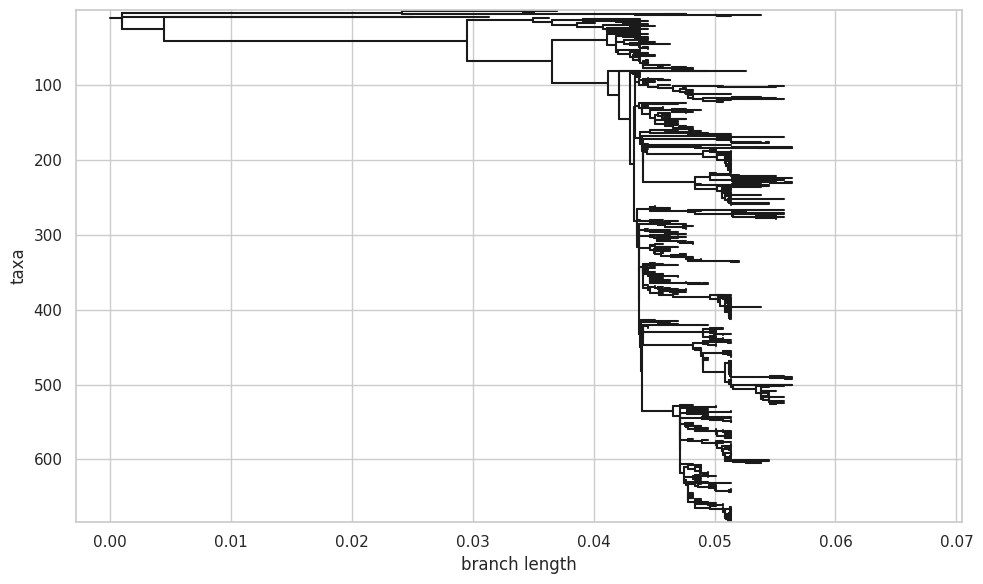

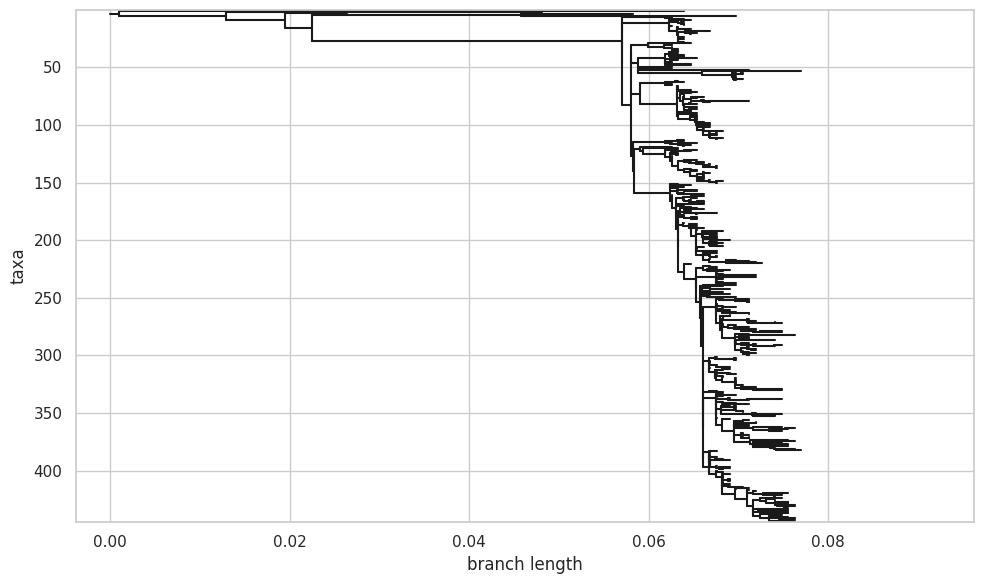

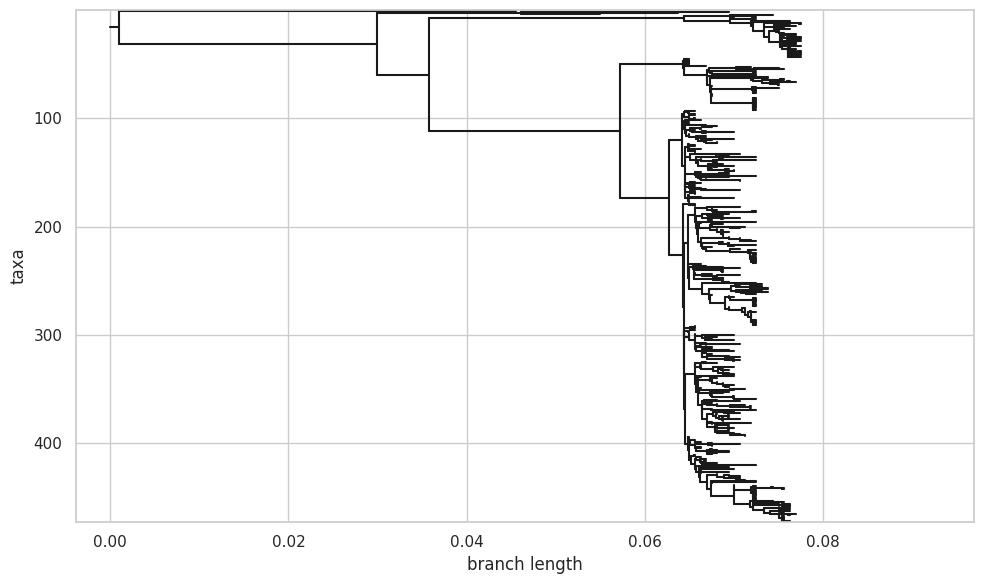

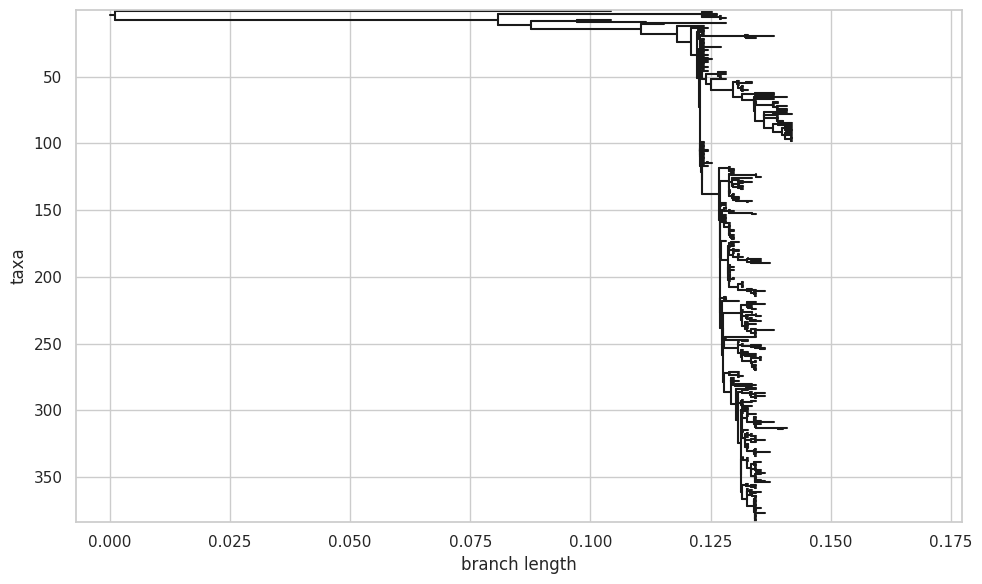

In [57]:
for i in range(4):
    sero = i+1
    tree = Phylo.read(TIME_TREE_EXP.format(sero), "newick")
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    Phylo.draw(
        tree,
        axes=ax,
        label_func=lambda x: None,
        branch_labels=False,
        do_show=False
    )
    
    plt.tight_layout()
    #plt.savefig("phylogenetic_tree.png", dpi=300)
    plt.show()

## Translate from refined tree using Augur

In [58]:
for i in range(4):
    sero = i+1
    print(f"Translating DENV{sero}")
    
    augur_translate(
        in_tree=TIME_TREE_EXP.format(sero),
        ancestral_seqs=ANCESTRAL_NODE_EXP.format(sero),
        ref_seq=TMP_GFF_EXP.format(serotype),
        genes=["E"],
        out_node=NODE_AA_EXP.format(sero),
        out_aln=AA_SEQS_EXP.format(sero)
    )

Translating DENV1


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV1_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV1_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV1_aa.json


Translating DENV2


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV2_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV2_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV2_aa.json


Translating DENV3


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV3_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV3_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV3_aa.json


Translating DENV4


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV4_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV4_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV4_aa.json


## Sequence Count

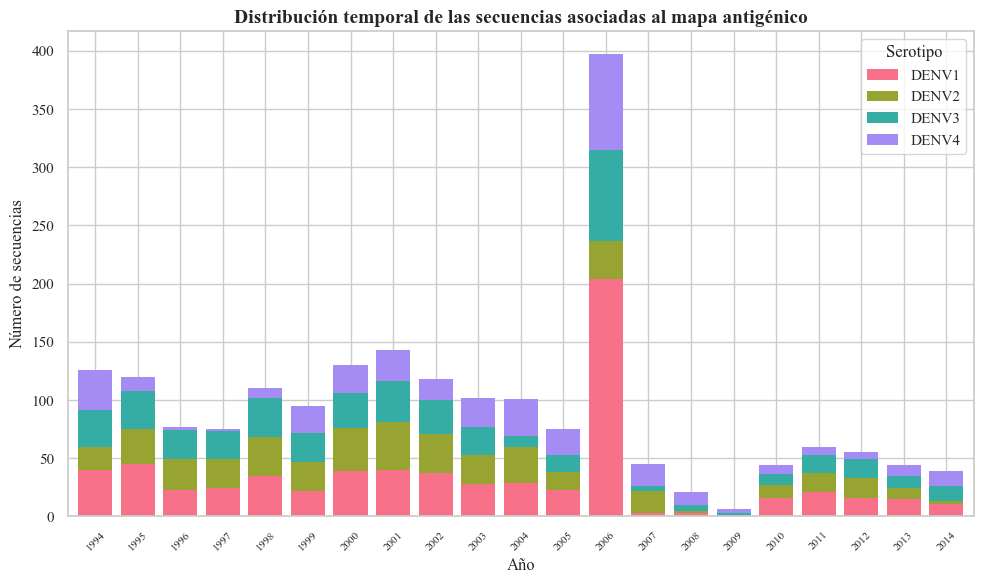

In [35]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "Times New Roman"
plot_data = []
all_years = None

for sero in range(1, 5):
    df = pd.read_csv(META_EXP.format(sero), sep="\t")
    df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
    df = df.dropna(subset=["date"])
    df["year"] = df["date"].dt.year

    counts = df.groupby("year").size()

    if all_years is None:
        all_years = range(
            counts.index.min(),
            counts.index.max() + 1
        )
    else:
        all_years = range(
            min(all_years[0], counts.index.min()),
            max(all_years[-1], counts.index.max()) + 1
        )

    counts = counts.reindex(all_years, fill_value=0).reset_index()
    counts.columns = ["year", "count"]
    counts["serotype"] = f"DENV{sero}"
    plot_data.append(counts)

plot_df = pd.concat(plot_data, ignore_index=True)

# Formato para stacked barplot
plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)
plot_pivot = plot_pivot.loc[1994:2014]
fig, ax = plt.subplots(figsize=(10, 6))

plot_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=sns.color_palette("husl", 4),
    width=0.8,
    linewidth=0
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Número de secuencias", fontsize=12)
ax.set_title(
    "Distribución temporal de las secuencias asociadas al mapa antigénico",
    fontsize=14,
    fontweight="bold"
)

ax.legend(title="Serotipo")
ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.show()

# Merged Data

In [94]:
def merge_fastas(f1, f2, out):
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    seen_ids = set()
    with open(out, "w") as out_f:
        for src, suffix in [(f1, "_COL"), (f2, "_EXP")]:
            with open(src, "r") as in_f:
                current_id = None
                for line in in_f:
                    if line.startswith(">"):
                        current_id = line[1:].strip().split()[0]
                        if current_id in seen_ids:
                            current_id = f"{current_id}{suffix}"
                            line = f">{current_id}\n"
                        seen_ids.add(current_id)
                    out_f.write(line)
    print(f"FASTA → {out}")

def merge_tsvs(f1, f2, out):
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    header = None
    with open(out, "w") as out_f:
        for src in (f1, f2):
            with open(src, "r") as in_f:
                for line in in_f:
                    stripped = line.strip()
                    # Preserve comments & empty lines
                    if stripped.startswith("#") or stripped == "":
                        out_f.write(line)
                        continue
                    # First non-comment line = header
                    if header is None:
                        header = stripped
                        out_f.write(line)
                    # Skip duplicate headers, write data
                    elif stripped != header:
                        out_f.write(line)
    print(f"TSV  → {out}")

def merge_gffs(f1, f2, out):
    """Merges GFF3 files, ensures ##gff-version appears only once at top."""
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    version_written = False
    with open(out, "w") as out_f:
        for src in (f1, f2):
            with open(src, "r") as in_f:
                for line in in_f:
                    stripped = line.strip()
                    if stripped.startswith("##gff-version"):
                        if not version_written:
                            out_f.write(line)
                            version_written = True
                        continue
                    out_f.write(line)
    print(f"GFF  → {out}")


SEROTYPES = [1, 2, 3, 4]

for sero in SEROTYPES:
    print(f"\n🔹 Processing DENV-{sero}...")
    merge_fastas(
        CROP_SEQS_COL.format(sero),
        CROP_SEQS_EXP.format(sero),
        CROP_SEQS_MERGE.format(sero)
    )
    merge_tsvs(
        META_CLEAN_COL.format(sero),
        META_EXP.format(sero),
        META_MERGE.format(sero)
    )
    merge_gffs(
        TMP_GFF_COL.format(sero),
        TMP_GFF_EXP.format(sero),
        TMP_GFF_MERGE.format(sero)
    )

print("All merges complete.")


🔹 Processing DENV-1...
FASTA → ../resources/merged_data/cropped/align_DENV1.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV1_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV1.gff

🔹 Processing DENV-2...
FASTA → ../resources/merged_data/cropped/align_DENV2.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV2_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV2.gff

🔹 Processing DENV-3...
FASTA → ../resources/merged_data/cropped/align_DENV3.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV3_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV3.gff

🔹 Processing DENV-4...
FASTA → ../resources/merged_data/cropped/align_DENV4.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV4_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV4.gff
All merges complete.


## Tree Augur Workflow

In [95]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_MERGE.format(serotype),
               out_tree=TREE_MERGE.format(serotype))
    
    augur_refine(in_tree=TREE_MERGE.format(serotype),
                 in_seqs=CROP_SEQS_MERGE.format(serotype),
                 in_meta=META_MERGE.format(serotype),
                 out_tree=TIME_TREE_MERGE.format(serotype),
                 out_node=NODE_TREE_MERGE.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_MERGE.format(serotype),
        in_seqs=CROP_SEQS_MERGE.format(serotype),
        out_node=ANCESTRAL_NODE_MERGE.format(serotype),
        out_seqs=ANCESTRAL_SEQS_MERGE.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 56.06650948524475 seconds
augur refine is using TreeTime version 0.11.4

0.39	TreeTime.reroot: with method or node: least-squares

0.39	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.92	TreeTime.reroot: with method or node: least-squares

0.92	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.
pruning leaf  hDenV1/Colombia/BOL-UEB-016/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-016-1/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152-1/2019

3.86	TreeTime.reroot: with method or node: least-squares

3.86	TreeTime.reroot: rer

Validating schema of '../resources/merged_data/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.953526735305786 seconds
augur refine is using TreeTime version 0.11.4

0.35	TreeTime.reroot: with method or node: least-squares

0.36	TreeTime.reroot: rerooting will ignore covari

Validating schema of '../resources/merged_data/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 49.995237827301025 seconds
augur refine is using TreeTime version 0.11.4

0.30	TreeTime.reroot: with method or node: least-squares

0.30	TreeTime.reroot: rerooting will ignore covari

Validating schema of '../resources/merged_data/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 46.55387997627258 seconds
augur refine is using TreeTime version 0.11.4

0.20	TreeTime.reroot: with method or node: least-squares

0.20	TreeTime.reroot: rerooting will ignore covaria

Validating schema of '../resources/merged_data/ancestral/E_DENV4_ancestral.json'...



DENV 1
Secuencias en FASTA del mapa: 105
Experimentales en mapa: 105
Ejemplos: ['DENV1/THAILAND/1996/01231/96', 'DENV1/THAILAND/2006/02193/06', 'DENV1/THAILAND/2006/00555/06', 'DENV1/PERU/2000/IQT-6152', 'DENV1/THAILAND/2010/00792/10']

DENV 2
Secuencias en FASTA del mapa: 86
Experimentales en mapa: 86
Ejemplos: ['DENV2/THAILAND/1997/05107/97', 'DENV2/THAILAND/2001/03693/01', 'DENV2/THAILAND/2014/00016/14', 'DENV2/THAILAND/2010/01363/10', 'DENV2/THAILAND/2011/00322/11']

DENV 3
Secuencias en FASTA del mapa: 102
Experimentales en mapa: 102
Ejemplos: ['DENV3/THAILAND/2011/01278/11', 'DENV3/THAILAND/1994/00128/94', 'DENV3/THAILAND/1994/00831/94', 'DENV3/THAILAND/2000/06135/00', 'DENV3/THAILAND/1998/06070/98']

DENV 4
Secuencias en FASTA del mapa: 92
Experimentales en mapa: 92
Ejemplos: ['DENV4/THAILAND/2004/00217/04', 'DENV4/THAILAND/2001/05386/01', 'DENV4/THAILAND/2007/01993/07', 'DENV4/THAILAND/1998/06523/98', 'DENV4/THAILAND/2011/00251/11']


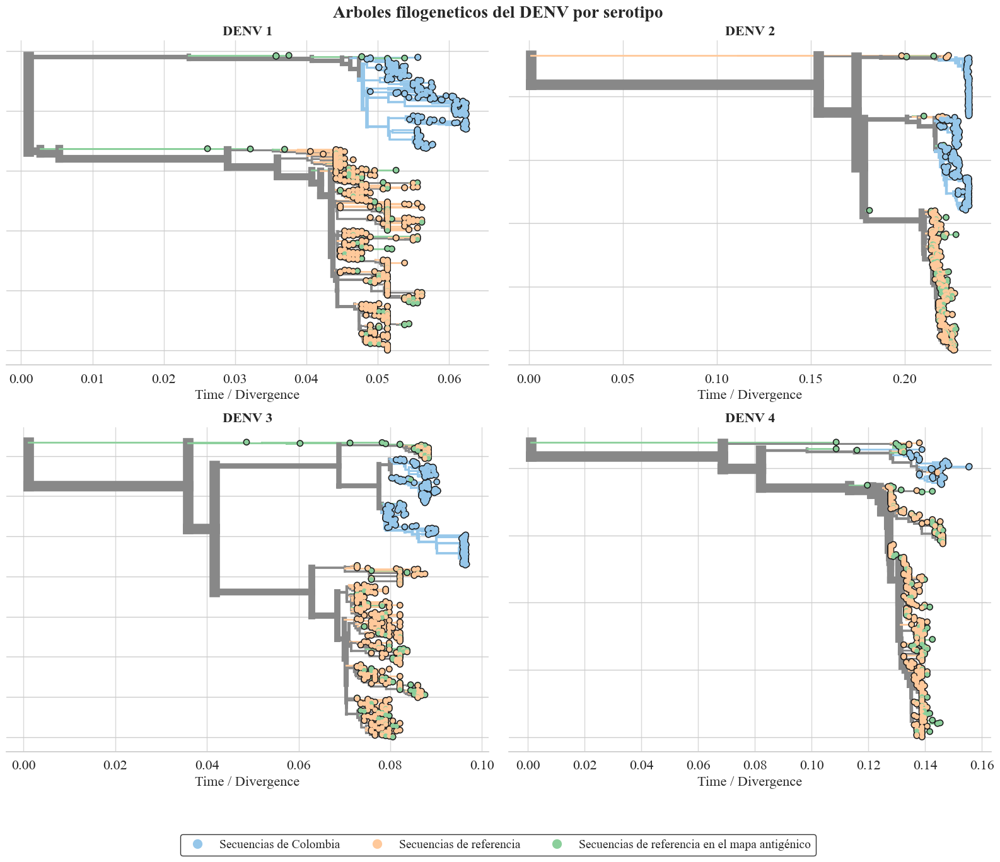

In [17]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

from Bio import SeqIO
from matplotlib.lines import Line2D
plt.rcParams["font.family"] = "Times New Roman"
# Colores
COLOR_COL = "#96c7ea"       
COLOR_EXP = "#ffc99b"       
COLOR_MAP = "#8bcf9b"       
COLOR_UNKNOWN = "#888888"


def clean_id(x):
    """
    Limpia un identificador sin dividirlo en tokens.
    """
    return str(x).strip()


def get_fasta_ids(fasta_path):
    """
    Obtiene los IDs completos de las secuencias del FASTA.
    """
    return {
        clean_id(record.id)
        for record in SeqIO.parse(fasta_path, "fasta")
    }


fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()


for idx, s in enumerate(range(4)):

    sero = s + 1
    ax = axes[idx]

    ll = bt.loadNewick(TIME_TREE_MERGE.format(sero))

    df = pd.read_csv(
        META_MERGE.format(sero),
        sep='\t'
    )

    df['country'] = (
        df['country']
        .fillna('')
        .str.strip()
        .str.lower()
    )

    map_fasta = AA_SEQS_EXP_E_map.format(sero)

    map_ids = get_fasta_ids(map_fasta)

    print(f"\nDENV {sero}")
    print(f"Secuencias en FASTA del mapa: {len(map_ids)}")

    origin_map = {}

    for _, row in df.iterrows():

        strain = clean_id(row['strain'])

        if 'colombia' in row['country']:
            origin = 'COL'
        else:
            origin = 'EXP'

        origin_map[strain] = origin

    experimental_map_ids = set()

    for strain, origin in origin_map.items():

        if origin == 'EXP' and strain in map_ids:
            experimental_map_ids.add(strain)

    print(
        f"Experimentales en mapa: "
        f"{len(experimental_map_ids)}"
    )

    # Mostrar algunas para verificar
    print(
        "Ejemplos:",
        list(experimental_map_ids)[:5]
    )

    leaf_colors = {}

    for k in ll.Objects:

        if k.branchType != 'leaf':
            continue

        name = clean_id(k.name)

        if origin_map.get(name) == 'COL':

            leaf_colors[name] = COLOR_COL

        elif origin_map.get(name) == 'EXP':

            if name in experimental_map_ids:
                leaf_colors[name] = COLOR_MAP
            else:
                leaf_colors[name] = COLOR_EXP

        else:

            leaf_colors[name] = COLOR_UNKNOWN

    def c_func(k):

        if k.branchType == 'leaf':
            return leaf_colors.get(
                k.name,
                COLOR_UNKNOWN
            )

        has_col = False
        has_exp = False
        has_map = False

        for d in k.leaves:

            d_name = d.name if hasattr(d, 'name') else d

            c = leaf_colors.get(
                d_name,
                COLOR_UNKNOWN
            )

            if c == COLOR_COL:
                has_col = True

            elif c == COLOR_EXP:
                has_exp = True

            elif c == COLOR_MAP:
                has_map = True

        # Si hay más de un tipo dentro del clado,
        # dejamos la rama gris
        n_types = sum([
            has_col,
            has_exp,
            has_map
        ])

        if n_types > 1:
            return COLOR_UNKNOWN

        if has_col:
            return COLOR_COL

        if has_map:
            return COLOR_MAP

        if has_exp:
            return COLOR_EXP

        return COLOR_UNKNOWN

    L = sum(
        1
        for k in ll.Objects
        if k.branchType == 'leaf'
    )

    b_func = lambda k: (
        2 + 10.0 * len(k.leaves) / L
        if k.branchType == 'node'
        else 2
    )

    ll.plotTree(
        ax,
        width=b_func,
        colour=c_func,
        zorder=20000
    )

    ll.plotPoints(
        ax,
        size=30,
        colour=c_func,
        zorder=20002
    )

    for loc in ['left', 'right', 'top']:
        ax.spines[loc].set_visible(False)

    ax.grid(
        axis='x',
        ls='-',
        color='grey',
        alpha=0.3
    )

    ax.tick_params(
        axis='y',
        size=0
    )

    ax.tick_params(
        axis='x',
        labelsize=16
    )

    ax.set_xlabel(
        'Time / Divergence',
        fontsize=16
    )

    ax.set_yticklabels([])

    ax.set_title(
        f"DENV {sero}",
        fontsize=16,
        fontweight='bold'
    )

fig.suptitle(
    "Arboles filogeneticos del DENV por serotipo",
    fontsize=20,
    fontweight='bold',
    y=0.98
)

legend_elements = [

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Secuencias de Colombia',
        markerfacecolor=COLOR_COL,
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Secuencias de referencia',
        markerfacecolor=COLOR_EXP,
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Secuencias de referencia en el mapa antigénico',
        markerfacecolor=COLOR_MAP,
        markersize=12
    )
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    fontsize=14,
    frameon=True,
    edgecolor='black',
    ncol=3
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    "../figures/DENV_all_serotypes_col_exp.jpeg",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

# Project Colombia data and Antigenic map data

Antígenos: 412
Antisueros: 36


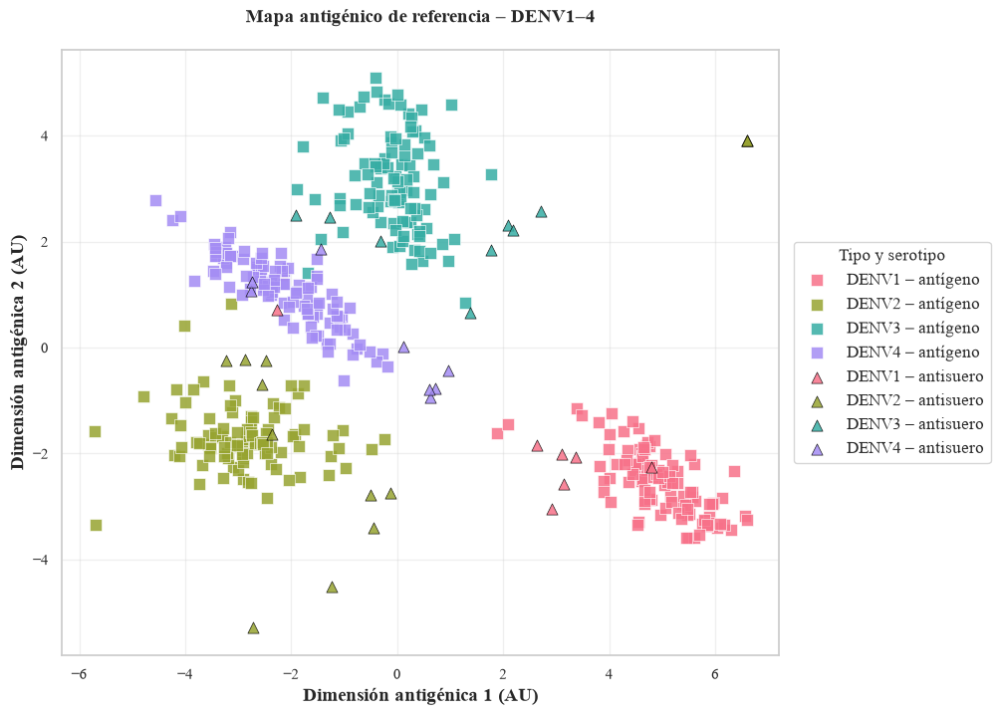

In [9]:
plt.rcParams["font.family"] = "Times New Roman"

mapa_ag = pd.read_csv(
    "../resources/experimental_data/2d-antigenic-map.txt",
    sep=r"\s+",
    header=None,
    names=["type", "strainID", "coord1", "coord2"]
)

# Extraer serotipo: acepta DENV1 y DEN1
mapa_ag["sero_num"] = mapa_ag["strainID"].str.extract(
    r"(?:DENV|DEN)(\d)",
    expand=False
)

mapa_ag["sero"] = "DENV" + mapa_ag["sero_num"]

# Separar antígenos y antisueros
antigenos = mapa_ag[mapa_ag["type"] == "AG"].copy()
sueros = mapa_ag[mapa_ag["type"] == "SR"].copy()

print(f"Antígenos: {len(antigenos)}")
print(f"Antisueros: {len(sueros)}")

unique_sero = sorted(mapa_ag["sero"].unique())

palette = sns.color_palette(
    "husl",
    n_colors=len(unique_sero)
)

color_dict = dict(zip(unique_sero, palette))

fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=color_dict[sero],
        marker="s",
        s=65,
        alpha=0.85,
        edgecolors="white",
        linewidth=0.5,
        label=f"{sero} – antígeno"
    )


for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=color_dict[sero],
        marker="^",
        s=65,
        alpha=0.85,
        edgecolors="black",
        linewidth=0.5,
        label=f"{sero} – antisuero"
    )


ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "Mapa antigénico de referencia – DENV1–4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.grid(
    True,
    alpha=0.3
)

# Leyenda
ax.legend(
    title="Tipo y serotipo",
    title_fontsize=12,
    fontsize=12,
    frameon=True,
    ncol=1,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)
ax.set_aspect("equal", adjustable="box")
plt.savefig(
    "../figures/mapa_ref.png",
    dpi=300,
    bbox_inches="tight"
)

In [10]:
info_viruses = pd.read_csv(
    "../resources/experimental_data/metadata/information.viruses.csv"
)

# Si antigenos ya tiene genotype, eliminarlo antes del merge
if "genotype" in antigenos.columns:
    antigenos = antigenos.drop(columns=["genotype"])

# Información de genotipo
info_genotype = (
    info_viruses[
        ["unified.sequence.names", "genotype"]
    ]
    .drop_duplicates(subset="unified.sequence.names")
)

# Agregar genotipo
antigenos = antigenos.merge(
    info_genotype,
    left_on="strainID",
    right_on="unified.sequence.names",
    how="left"
)

# Eliminar columna auxiliar
antigenos = antigenos.drop(columns=["unified.sequence.names"])

# País
antigenos["country"] = (
    antigenos["strainID"]
    .str.split("/")
    .str[1]
    .str.strip()
    .str.title()
)

# Distribución de genotipos por serotipo
tabla_genotipos = (
    antigenos
    .groupby(["sero", "genotype"])
    .size()
    .reset_index(name="n")
)

tabla = (
    antigenos
    .groupby(["sero", "genotype"])
    .agg(
        n=("strainID", "size"),
        paises=("country", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

# Ordenar genotipos por frecuencia dentro de cada serotipo
tabla = (
    tabla
    .sort_values(["sero", "n"], ascending=[True, False])
)

print(tabla.to_string(index=False))

 sero             genotype  n                                                       paises
DENV1              DENV1-I 95                         Cambodia, Myanmar, Thailand, Vietnam
DENV1              DENV1-V  8               Bolivia, Peru, Puertorico, Thailand, Venezuela
DENV1             DENV1-II  1                                                     Thailand
DENV1             DENV1-IV  1                                                        Nauru
DENV2        DENV2-Asian I 83                                           Cambodia, Thailand
DENV2 DENV2-Asian/American  7                 Brazil, Guyana, Nicaragua, Thailand, Vietnam
DENV2   DENV2-Cosmopolitan  4                                     India, Thailand, Vietnam
DENV2       DENV2-American  2                                                  Peru, Tonga
DENV2       DENV2-Sylvatic  2                                            Malaysia, Senegal
DENV2       DENV2-Asian II  1                                                    Newguinea

In [11]:
valid_strain_ids = set(mapa_ag['strainID'].astype(str).tolist())
print(f"Total de cepas de referencia válidas en mapa_ag: {len(valid_strain_ids)}")

serotypes = [1, 2, 3, 4]

print("\nFiltrando secuencias experimentales...")
for sero in serotypes:
    input_fasta = AA_SEQS_EXP_E.format(sero)
    output_fasta = AA_SEQS_EXP_E_map.format(sero)
    
    all_records = list(SeqIO.parse(input_fasta, "fasta"))
    total_seqs = len(all_records)
    
    filtered_records = [r for r in all_records if r.id in valid_strain_ids]
    kept_seqs = len(filtered_records)
    
    SeqIO.write(filtered_records, output_fasta, "fasta")
    
    print(f"  DENV{sero}: Conservadas {kept_seqs} / {total_seqs} secuencias.")
    print(f"          -> Guardado en: {output_fasta}")

Total de cepas de referencia válidas en mapa_ag: 448

Filtrando secuencias experimentales...
  DENV1: Conservadas 105 / 1316 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV1_aa_E_map.fasta
  DENV2: Conservadas 86 / 871 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV2_aa_E_map.fasta
  DENV3: Conservadas 102 / 928 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV3_aa_E_map.fasta
  DENV4: Conservadas 92 / 740 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV4_aa_E_map.fasta


DENV1: 105 secuencias presentes en el mapa antigénico
DENV2: 86 secuencias presentes en el mapa antigénico
DENV3: 102 secuencias presentes en el mapa antigénico
DENV4: 92 secuencias presentes en el mapa antigénico


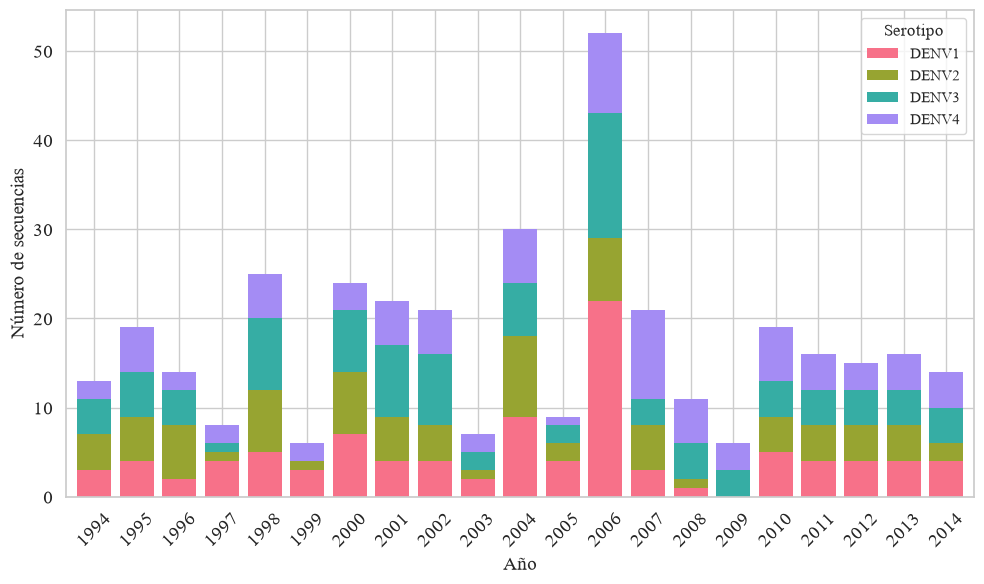

In [12]:
plt.rcParams["font.family"] = "Times New Roman"

plot_data = []

for sero in range(1, 5):
    
    fasta_file = AA_SEQS_EXP_E_map.format(sero)

    records = list(SeqIO.parse(fasta_file, "fasta"))

    valid_ids = {
        record.id.strip()
        for record in records
    }

    print(
        f"DENV{sero}: {len(valid_ids)} secuencias "
        f"presentes en el mapa antigénico"
    )

    df = pd.read_csv(
        META_EXP.format(sero),
        sep="\t"
    )

    df["strain"] = (
        df["strain"]
        .astype(str)
        .str.strip()
    )

    df = df[
        df["strain"].isin(valid_ids)
    ].copy()

    df["date"] = pd.to_datetime(
        df["date"],
        format="mixed",
        errors="coerce"
    )

    df = df.dropna(subset=["date"])

    df["year"] = df["date"].dt.year

    counts = (
        df.groupby("year")
        .size()
        .reindex(
            range(1994, 2015),
            fill_value=0
        )
        .reset_index()
    )

    counts.columns = [
        "year",
        "count"
    ]

    counts["serotype"] = f"DENV{sero}"

    plot_data.append(counts)


plot_df = pd.concat(
    plot_data,
    ignore_index=True
)


plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)

plot_pivot = plot_pivot[
    ["DENV1", "DENV2", "DENV3", "DENV4"]
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)

plot_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=sns.color_palette("husl", 4),
    width=0.8,
    linewidth=0
)

ax.set_xlabel(
    "Año",
    fontsize=14
)

ax.set_ylabel(
    "Número de secuencias",
    fontsize=14
)
'''
ax.set_title(
    "Distribución temporal de las secuencias asociadas al mapa antigénico",
    fontsize=14,
    fontweight="bold"
)
'''
ax.legend(
    title="Serotipo"
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=14
)
ax.tick_params(
    axis="y",
    labelsize=14
)

plt.tight_layout()
plt.savefig("../figures/distribucion_temporal_ref.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [16]:
serotypes = range(1, 5) 

output_file = "../resources/merged_all_E_sequences.fasta"

def parse_fasta(file_path):
    header = None
    sequence = []
    with open(file_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith('>'):
                if header is not None:
                    yield header, ''.join(sequence)
                header = line
                sequence = []
            else:
                sequence.append(line)
        if header is not None:
            yield header, ''.join(sequence)

with open(output_file, 'w') as out_f:
    for i in range(1, 5): 
        
        exp_path = AA_SEQS_EXP_E_map.format(i)
        if os.path.exists(exp_path):
            for header, seq in parse_fasta(exp_path):
                out_f.write(f"{header}\n{seq}\n")
        
        col_path = AA_SEQS_COL_E.format(i)
        if os.path.exists(col_path):
            for header, seq in parse_fasta(col_path):
                if not header.startswith('>NODE'):
                    out_f.write(f"{header}\n{seq}\n")

print(f"Successfully merged and filtered files into: {output_file}")

Successfully merged and filtered files into: ../resources/merged_all_E_sequences.fasta


In [19]:
def compute_grantham_matrices(
    fasta_col_template: str,
    fasta_exp_template: str,
    meta_col_template: str,
    meta_exp_template: str,
    serotypes: Optional[List[int]] = None,
    exclude_prefix: str = "NODE",
    output_meta_dir: str = "merged_metadata",
    metric="grantham"
) -> Tuple[List[pd.DataFrame], str]:
    
    if serotypes is None:
        serotypes = [1, 2, 3, 4]
        
    os.makedirs(output_meta_dir, exist_ok=True)
    all_exp_records = []
    for sero in serotypes:
        records = [r for r in SeqIO.parse(fasta_exp_template.format(sero), "fasta") 
                   if not r.id.startswith(exclude_prefix)]
        all_exp_records.extend(records)
    
    all_exp_ids = [r.id for r in all_exp_records]
    all_exp_seqs = [str(r.seq) for r in all_exp_records]
    n_all_exp = len(all_exp_seqs)
    
    print(f"Conjunto unificado de referencias experimentales: {n_all_exp} secuencias")
    
    matrices = []
    
    for sero in serotypes:
        print(f"Procesando DENV{sero}...")
        
        records_col = [r for r in SeqIO.parse(fasta_col_template.format(sero), "fasta") 
                       if not r.id.startswith(exclude_prefix)]
        
        ids_col = [r.id for r in records_col]
        seqs_col = [str(r.seq) for r in records_col]
        n_col = len(seqs_col)
        
        matrix = np.full((n_col, n_all_exp), np.nan)
        for i in range(n_col):
            for j in range(n_all_exp):
                matrix[i, j] = antigenic_distance(seqs_col[i], all_exp_seqs[j], sero, type=metric)
                
        df_matrix = pd.DataFrame(matrix, index=ids_col, columns=all_exp_ids)
        matrices.append(df_matrix)
        
        meta_col = pd.read_csv(meta_col_template.format(sero), sep="\t")
        meta_exp = pd.read_csv(meta_exp_template.format(sero), sep="\t")

        for df in [meta_col, meta_exp]:
            if "strain" not in df.columns:
                df["strain"] = df.iloc[:, 0]
                
        meta_merged = pd.concat([meta_col, meta_exp], ignore_index=True).drop_duplicates(subset=["strain"])
        merged_path = f"{output_meta_dir}/meta_merged_{sero}.tsv"
        meta_merged.to_csv(merged_path, sep="\t", index=False)
        
    merged_template = f"{output_meta_dir}/meta_merged_{{}}.tsv"
    return matrices, merged_template

In [20]:
df_matrices, meta_tmpl = compute_grantham_matrices(
    fasta_col_template=AA_SEQS_COL_E,
    fasta_exp_template=AA_SEQS_EXP_E_map,
    meta_col_template=META_CLEAN_COL,
    meta_exp_template=META_EXP,
    serotypes=[1, 2, 3, 4]
)

Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


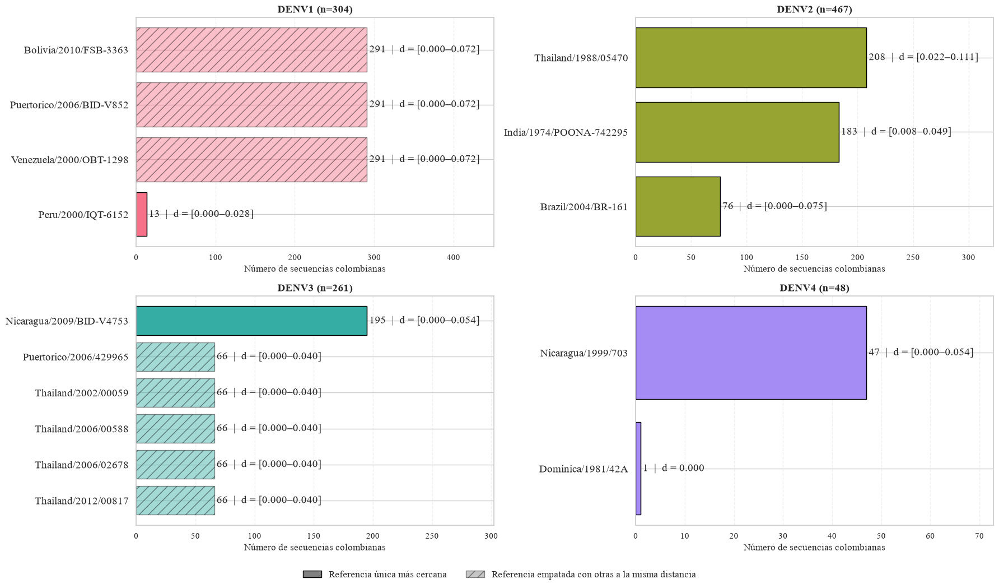

In [16]:
from matplotlib.patches import Patch

def ref_label(ref_id):
    p = ref_id.split("/")
    pais = p[1].title()
    anio = p[2]
    rid  = p[3]
    return f"{pais}/{anio}/{rid}"

def country(ref_id):
    return ref_id.split("/")[1].title()

def fmt_dist(vals):
    vals = np.asarray(vals, dtype=float)
    lo, hi = vals.min(), vals.max()
    if np.isclose(lo, hi, atol=1e-9):
        return f"d = {lo:.3f}"
    return f"d = [{lo:.3f}–{hi:.3f}]"
atol = 1e-9
# ---- 1) Tabla detallada ----
rows = []
for sero, matrix in zip(serotypes, df_matrices):
    d = matrix.values.astype(float)
    for i, strain in enumerate(matrix.index):
        if np.isnan(d[i]).all():
            continue
        dmin = np.nanmin(d[i])
        tied_refs = list(matrix.columns[np.isclose(d[i], dmin, atol=atol)])
        rows.append({
            "serotype": sero,
            "seq_col": strain,
            "min_distance": dmin,
            "n_refs_tied": len(tied_refs),
            "n_countries_tied": len({country(r) for r in tied_refs}),
            "countries_tied": ";".join(sorted({country(r) for r in tied_refs})),
            "labels_tied": ";".join(ref_label(r) for r in tied_refs),
            "refs_tied": ";".join(tied_refs),
        })
df_matches = pd.DataFrame(rows)
df_matches.to_csv("../output/closest_matches_detail.tsv", sep="\t", index=False)

# ---- 2) Figura ----
top_n = 10
colors = sns.color_palette("husl", n_colors=len(serotypes))
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

for ax, sero, color in zip(axes.flatten(), serotypes, colors):
    sub = df_matches[df_matches.serotype == sero]

    uniq, tied = {}, {}
    dist_by_label = {}
    for _, r in sub.iterrows():
        target = uniq if r.n_refs_tied == 1 else tied
        for lab in r.labels_tied.split(";"):
            target[lab] = target.get(lab, 0) + 1
            dist_by_label.setdefault(lab, []).append(r.min_distance)

    cnt = pd.DataFrame({"unico": pd.Series(uniq, dtype=float),
                        "empatado": pd.Series(tied, dtype=float)}).fillna(0)
    cnt["total"] = cnt.sum(axis=1)
    cnt = cnt.sort_values("total", ascending=False).head(top_n).iloc[::-1]

    ax.barh(cnt.index, cnt["unico"], color=color, edgecolor="black")
    ax.barh(cnt.index, cnt["empatado"], left=cnt["unico"], color=color, alpha=0.45,
            edgecolor="black", hatch="//")

    xmax = cnt["total"].max()
    for y, (lab, u, t) in enumerate(zip(cnt.index, cnt["unico"], cnt["empatado"])):
        ax.text(u + t + xmax * 0.01, y,
                f"{int(u + t)}  |  {fmt_dist(dist_by_label[lab])}",
                va="center", fontsize=14)

    pct_tied = (sub.n_refs_tied > 1).mean() * 100
    ax.set_title(f"DENV{sero} (n={len(sub)})", fontsize=14, fontweight="bold")
    ax.set_xlabel("Número de secuencias colombianas")
    ax.tick_params(axis="y", labelsize=14)
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_xlim(0, xmax * 1.55)

handles = [Patch(facecolor="grey", edgecolor="black", label="Referencia única más cercana"),
           Patch(facecolor="grey", alpha=0.45, edgecolor="black", hatch="//",
                 label="Referencia empatada con otras a la misma distancia")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=12, frameon=False)
#fig.suptitle("Referencias experimentales más cercanas a las secuencias colombianas",fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.savefig("../figures/closest_experimental_matches.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
for s in [2, 3, 4]:
    sub = df_matches[(df_matches.serotype == s) & (df_matches.n_refs_tied == 1)]
    print(f"DENV{s} (sin empate, n={len(sub)})")
    print((sub.countries_tied.value_counts(normalize=True) * 100).round(1), "\n")

DENV2 (sin empate, n=467)
countries_tied
Thailand    44.5
India       39.2
Brazil      16.3
Name: proportion, dtype: float64 

DENV3 (sin empate, n=195)
countries_tied
Nicaragua    100.0
Name: proportion, dtype: float64 

DENV4 (sin empate, n=48)
countries_tied
Nicaragua    97.9
Dominica      2.1
Name: proportion, dtype: float64 



In [22]:
def epitope_sites(sero):
    locs = [[47,47],[123,126],[148,165],[167,167],[170,177],[180,180],[279,279],[293,293],
            [67,74],[76,79],[88,88],[97,118],[215,215],[219,219],[233,233],[237,237],
            [244,249],[256,256],[266,268],[272,276],
            [282,282],[298,311],[314,370],[372,372],[382,385],[387,390]]
    sites = [p for a, b in locs for p in range(a, b + 1)]
    return sites  # en numeración 1-based de DENV1/2/4

# Ajusta estos IDs a tus referencias de DENV2
ref_th, ref_br = "DENV2/THAILAND/1988/05470/88", "DENV2/BRAZIL/2004/BR-161"
seqs = {r.id: str(r.seq) for r in SeqIO.parse(AA_SEQS_EXP_E_map.format(2), "fasta")}
col_seqs = {r.id: str(r.seq) for r in SeqIO.parse(CROP_SEQS_EXP.format(2), "fasta")}

# Sitios donde difieren las dos referencias
diff = [p for p in epitope_sites(2) if seqs[ref_th][p-1] != seqs[ref_br][p-1]]
print(len(diff), "sitios epitópicos distinguen Tailandia de Brasil")

# Qué residuo tiene la mayoría de las colombianas en esos sitios
from collections import Counter
for p in diff:
    cons = Counter(s[p-1] for s in col_seqs.values()).most_common(1)[0][0]
    print(f"sitio {p}: TH={seqs[ref_th][p-1]}  BR={seqs[ref_br][p-1]}  Colombia(consenso)={cons}")

2 sitios epitópicos distinguen Tailandia de Brasil
sitio 170: TH=I  BR=T  Colombia(consenso)=G
sitio 340: TH=M  BR=T  Colombia(consenso)=G


In [23]:
# Posición en el mapa de las referencias empatadas más frecuentes
m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
dfm = df_matrices[0]
d = dfm.values.astype(float)
dmin = np.nanmin(d, axis=1)
tied = dfm.columns[np.isclose(d[0], dmin[0], atol=1e-9)]
print(m.reindex(tied)[['coord1', 'coord2']])

                                  coord1    coord2
DENV1/BOLIVIA/2010/FSB-3363     6.353862 -2.327160
DENV1/PUERTORICO/2006/BID-V852  6.137328 -2.839690
DENV1/VENEZUELA/2000/OBT-1298   6.593397 -3.250635


In [77]:
def get(sero):
    return str(next(iter(SeqIO.parse(AA_SEQS_EXP_E_map.format(sero), "fasta"))).seq)

def chk(sero, sites):
    s = get(sero)
    off = lambda p: p - 2 if (sero == 3 and p > 159) else p   # deleción DENV3
    for p, aa in sites.items():
        q = off(p)
        print(f"DENV{sero} {aa}{p}: 1-based={s[q-1]} | 0-based={s[q]}  "
              f"{'OK' if s[q-1]==aa else '--'}")

# DENV2 (filas DV2-44, DV2-76, 3H2/2C8, 1A1D-2)
chk(2, {88:'K', 233:'Q', 244:'H', 282:'V', 309:'V', 310:'K',
        361:'K', 383:'E', 384:'P'})

# J8/J9, DENV1-4: K47, H149, V151, F279
for sero in [1, 2, 3, 4]:
    chk(sero, {47:'K', 149:'H', 151:'V', 279:'F'})

# DENV4, 1G6: 387-ALTLH-390 con T388 y H390
s4 = get(4)
print("DENV4 s[385:390] =", s4[385:390], "(esperado ALTLH, posiciones 386-390)")

DENV2 K88: 1-based=K | 0-based=R  OK
DENV2 Q233: 1-based=Q | 0-based=K  OK
DENV2 H244: 1-based=H | 0-based=A  OK
DENV2 V282: 1-based=H | 0-based=L  --
DENV2 V309: 1-based=V | 0-based=K  OK
DENV2 K310: 1-based=K | 0-based=E  OK
DENV2 K361: 1-based=K | 0-based=D  OK
DENV2 E383: 1-based=E | 0-based=P  OK
DENV2 P384: 1-based=P | 0-based=G  OK
DENV1 K47: 1-based=K | 0-based=T  OK
DENV1 H149: 1-based=H | 0-based=Q  OK
DENV1 V151: 1-based=V | 0-based=G  OK
DENV1 F279: 1-based=F | 0-based=A  OK
DENV2 K47: 1-based=K | 0-based=T  OK
DENV2 H149: 1-based=H | 0-based=A  OK
DENV2 V151: 1-based=V | 0-based=G  OK
DENV2 F279: 1-based=F | 0-based=T  OK
DENV3 K47: 1-based=K | 0-based=T  OK
DENV3 H149: 1-based=H | 0-based=Q  OK
DENV3 V151: 1-based=V | 0-based=G  OK
DENV3 F279: 1-based=F | 0-based=A  OK
DENV4 K47: 1-based=K | 0-based=T  OK
DENV4 H149: 1-based=H | 0-based=A  OK
DENV4 V151: 1-based=V | 0-based=G  OK
DENV4 F279: 1-based=F | 0-based=A  OK
DENV4 s[385:390] = ALTLH (esperado ALTLH, posiciones 38

# Antigenic Space Projection

In [23]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = f"../output/antigenic_distances_DENV{sero}.csv"
    df_matrices[i].to_csv(filename, index=True, na_rep='NaN')
    
    print(f"Matriz de DENV{sero} exportada a: {filename}")

Matriz de DENV1 exportada a: ../output/antigenic_distances_DENV1.csv
Matriz de DENV2 exportada a: ../output/antigenic_distances_DENV2.csv
Matriz de DENV3 exportada a: ../output/antigenic_distances_DENV3.csv
Matriz de DENV4 exportada a: ../output/antigenic_distances_DENV4.csv


In [21]:
if df_matrices[i] is None or df_matrices[i].empty:
    for i, sero in enumerate([1, 2, 3, 4]):
        filename = f"../output/antigenic_distances_DENV{sero}.csv"
        if os.path.exists(filename):
            df_matrices[i] = pd.read_csv(
                filename,
                index_col=0
            )
            print(f"Matriz de DENV{sero} cargada desde: {filename}")
        else:
            print(f"No existe el archivo para DENV{sero}: {filename}")
            continue
    
        df_matrices[i].to_csv(
            filename,
            index=True,
            na_rep="NaN"
        )
    
        print(f"Matriz de DENV{sero} exportada a: {filename}")

NameError: name 'i' is not defined


Generando un unico mapa de calor combinado (todos los serotipos)...


D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


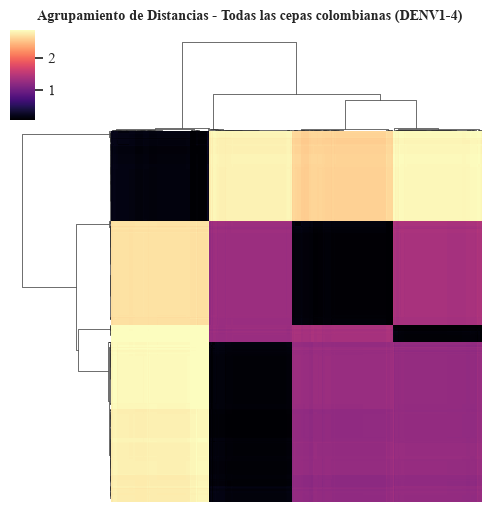

  Guardado: clustermap_DENV_all_combined.png


In [25]:
print("\nGenerando un unico mapa de calor combinado (todos los serotipos)...")

combined_df = pd.concat(df_matrices, axis=0)

g = sns.clustermap(
    combined_df, 
    cmap='magma', 
    xticklabels=False, 
    yticklabels=False,
    figsize=(5, 5),
    robust=True
)

g.fig.suptitle('Agrupamiento de Distancias - Todas las cepas colombianas (DENV1-4)', y=1.02, fontsize=10, fontweight='bold')
g.savefig('../figures/clustermap_DENV_all_combined.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("  Guardado: clustermap_DENV_all_combined.png")

In [15]:
def project_one(d, ref_xy, scale=None, eps=1e-6):
    d = d.astype(float).copy()
    nan = np.isnan(d)
    if nan.all():
        d[:] = 1.0
    else:
        d[nan] = np.nanmax(d)
    w = 1.0 / (d + eps); w /= w.sum()
    a0 = (w[:, None] * ref_xy).sum(axis=0)
    if scale is None:
        mx = d.max()
        target = d / mx if mx > 0 else d
    else:
        target = scale[0] * d + scale[1]
    res = lambda a: w * (np.linalg.norm(ref_xy - a, axis=1) - target)
    try:
        return least_squares(res, a0, method='lm', max_nfev=100,
                             ftol=1e-8, xtol=1e-8, gtol=1e-8).x
    except Exception:
        return a0

In [14]:
def project_strains(df_matrices, mapa_ag, scales=None, same_sero_only=False):
    """Para cepas que NO están en el mapa (p. ej. las colombianas)."""
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    col_sero = m.reindex(cols)['sero_num'].astype(int).values

    # Aviso si alguna cepa a proyectar ya está entre las referencias (fuga)
    for s in [1, 2, 3, 4]:
        overlap = set(df_matrices[s - 1].index) & set(cols)
        if overlap:
            print(f"DENV{s}: {len(overlap)} cepas también están en las referencias")

    out = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        keep = (col_sero == s) if same_sero_only else np.ones(len(cols), bool)
        sc = scales[s] if scales else None
        xy = np.array([project_one(row[keep], ref_xy[keep], sc) for row in dfm.values])
        out[s] = pd.DataFrame(xy, index=dfm.index, columns=['X', 'Y'])
    return out

In [25]:
projected_coordinates = project_strains(df_matrices, mapa_ag)
[print(f"{key}: {value.head()}") for key, value in projected_coordinates.items()]

1:                                                    X         Y
DenV1/mosquito/Colombia/MAG-CIST-0134/2018  6.361507 -2.805834
DenV1/mosquito/Colombia/MAG-CIST-0151/2018  6.361507 -2.805834
DenV1/un/Colombia/un-UniNorte-1/2001        4.386362 -2.371213
hDenV1/Colombia/ANT-INS-485061/2016         6.361507 -2.805834
hDenV1/Colombia/ANT-UDEA-COA0053/2021       6.361507 -2.805834
2:                                                 X         Y
DenV2/Colombia/VAC-LSPVAC-01056-VI/2024 -2.892731 -1.738809
DenV2/Colombia/VAC-LSPVAC-01460-VI/2024 -3.544748 -1.291697
DenV2/Colombia/VAC-LSPVAC-01585-VI/2024 -3.544748 -1.291697
DenV2/Colombia/VAC-LSPVAC-01723-VI/2024 -3.544748 -1.291697
DenV2/Colombia/VAC-LSPVAC-01759-VI/2024 -2.848525 -1.722060
3:                                              X         Y
hDenV3/Colombia/ANT-UDS-0109587/2012 -1.887791  2.979639
hDenV3/Colombia/ANT-UDS-0221590/2013 -1.887791  2.979639
hDenV3/Colombia/ANT-UDS-0267594/2014 -1.887791  2.979639
hDenV3/Colombia/ANT-UDS-0

[None, None, None, None]

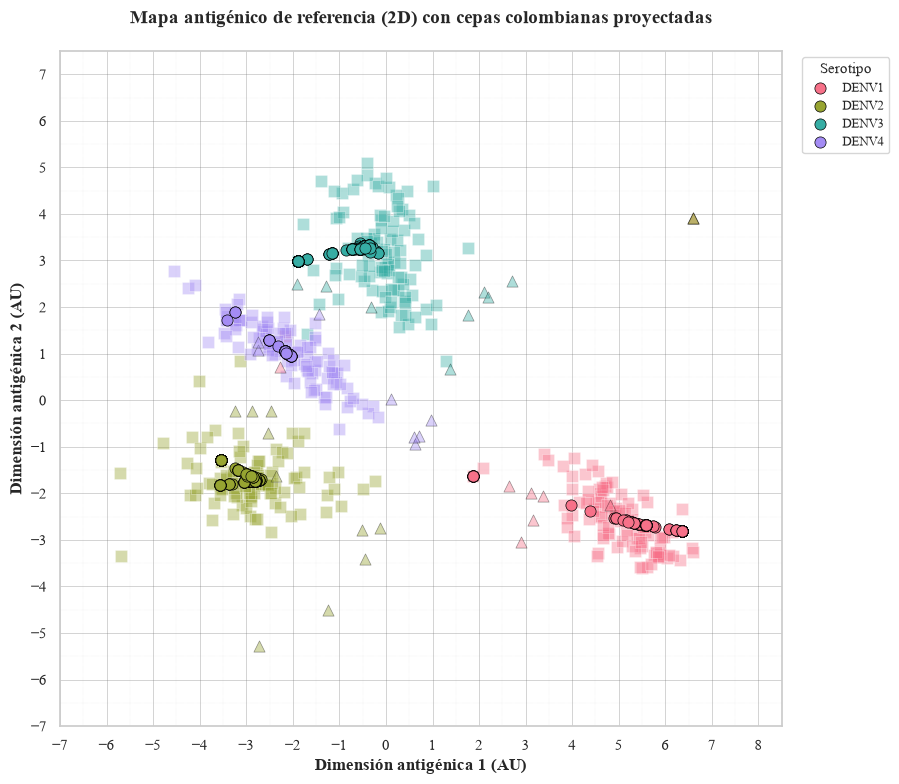

In [21]:
fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

# Referencia (Antígenos)
for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="s",
        s=65,
        alpha=0.4,
        edgecolors="white",
        linewidth=0.5
    )

# Referencia (Antisueros)
for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="^",
        s=65,
        alpha=0.4,
        edgecolors="black",
        linewidth=0.5
    )

# Cepas Colombianas Proyectadas
for sero in [1, 2, 3, 4]:
    sero_str = f"DENV{sero}"
    if sero in projected_coordinates:
        df_proj = projected_coordinates[sero]
        ax.scatter(
            df_proj["X"], df_proj["Y"],
            color=color_dict[sero_str],
            marker="o",
            s=65,
            alpha=1,
            edgecolors="black",
            linewidth=0.5,
            label=f"{sero_str}"
        )




all_x = np.concatenate([
    antigenos["coord1"].values,
    sueros["coord1"].values,
    *[projected_coordinates[s]["X"].values for s in projected_coordinates]
])
all_y = np.concatenate([
    antigenos["coord2"].values,
    sueros["coord2"].values,
    *[projected_coordinates[s]["Y"].values for s in projected_coordinates]
])

x_min, x_max = np.floor(all_x.min()) - 1, np.ceil(all_x.max()) + 1
y_min, y_max = np.floor(all_y.min()) - 1, np.ceil(all_y.max()) + 1

ax.set_xticks(np.arange(x_min, x_max + 1, 1))
ax.set_yticks(np.arange(y_min, y_max + 1, 1))

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(
    True,
    which="major",
    linestyle="-",
    linewidth=0.6,
    color="gray",
    alpha=0.4
)

ax.set_xticks(np.arange(x_min, x_max + 1, 0.5), minor=True)
ax.set_yticks(np.arange(y_min, y_max + 1, 0.5), minor=True)
ax.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.3,
    color="gray",
    alpha=0.25
)




ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_title(
    "Mapa antigénico de referencia (2D) con cepas colombianas proyectadas",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.legend(
    title="Serotipo",
    title_fontsize=11,
    fontsize=9,
    frameon=True,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig(
    "../figures/mapa_proy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [30]:
df_matrices_val, meta_tmpl = compute_grantham_matrices(
    fasta_col_template=AA_SEQS_EXP_E_map,
    fasta_exp_template=AA_SEQS_EXP_E_map,
    meta_col_template=META_EXP,
    meta_exp_template=META_EXP,
    serotypes=[1, 2, 3, 4]
)

Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [ ]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = f"../output/ref_antigenic_distances_DENV{sero}.csv"
    df_matrices_val[i].to_csv(filename, index=True, na_rep='NaN')
    
    print(f"Matriz de DENV{sero} exportada a: {filename}")

In [31]:
def validate_loo(df_matrices, mapa_ag, same_sero_only=False,
                 calibrate=False, drop_identical=False):
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    sizes = [len(d) for d in df_matrices]
    col_sero = np.repeat([1, 2, 3, 4], sizes)
    if calibrate:
        same_sero_only = True   # la escala se calibra intra-serotipo

    results = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        ids = dfm.index.tolist()
        D = dfm.values.astype(float)
        in_s = (col_sero == s)

        if calibrate:
            Ds = D[:, in_s]                                  # n x n, mismo serotipo
            assert dfm.columns[in_s].tolist() == ids          # mismo orden filas/columnas
            Dm = cdist(m.loc[ids, ['coord1', 'coord2']].values,
                       m.loc[ids, ['coord1', 'coord2']].values)
            off = ~np.eye(len(ids), dtype=bool) & ~np.isnan(Ds)

        rows = []
        for i, sid in enumerate(ids):
            keep = np.array([c != sid for c in cols])          # quita la propia cepa por ID
            if same_sero_only:
                keep &= in_s
            if drop_identical:
                keep &= ~(D[i] <= 1e-9)                        # quita casi-duplicados (NaN -> False)
            d, ref = D[i, keep], ref_xy[keep]

            scale = None
            if calibrate:                                      # calibración SIN la cepa evaluada
                pm = off.copy(); pm[i, :] = False; pm[:, i] = False
                scale = np.polyfit(Ds[pm], Dm[pm], 1)

            px, py = project_one(d, ref, scale)

            # líneas base con los mismos candidatos (mismo serotipo, sin la propia)
            same = in_s & np.array([c != sid for c in cols])
            mean_xy = ref_xy[same].mean(axis=0)
            dd = np.where(np.isnan(D[i]), np.inf, D[i]); dd[~same] = np.inf
            nn_xy = ref_xy[np.argmin(dd)]

            rx, ry = m.loc[sid, ['coord1', 'coord2']]
            rows.append(dict(strainID=sid, real_X=rx, real_Y=ry, proj_X=px, proj_Y=py,
                             mean_X=mean_xy[0], mean_Y=mean_xy[1],
                             nn_X=nn_xy[0], nn_Y=nn_xy[1]))
        results[s] = pd.DataFrame(rows).set_index('strainID')
    return results


def resumen(results):
    out = []
    for s, df in results.items():
        def rmse(a, b):
            return np.sqrt(np.mean((df[f'{a}_X'] - df['real_X'])**2 +
                                   (df[f'{a}_Y'] - df['real_Y'])**2))
        r_p, r_m, r_n = rmse('proj', 'x'), rmse('mean', 'x'), rmse('nn', 'x')
        out.append(dict(Serotipo=f'DENV-{s}', n=len(df),
                        r_X=stats.pearsonr(df.real_X, df.proj_X)[0],
                        r_Y=stats.pearsonr(df.real_Y, df.proj_Y)[0],
                        RMSE_proy=r_p, RMSE_media=r_m, RMSE_vecino=r_n,
                        skill_vs_media=1 - r_p / r_m))
    return pd.DataFrame(out).round(4)

In [33]:
from scipy.spatial.distance import cdist

base = validate_loo(df_matrices_val, mapa_ag)
print(resumen(base))
print(resumen(validate_loo(df_matrices_val, mapa_ag, same_sero_only=True)))
print(resumen(validate_loo(df_matrices_val, mapa_ag, calibrate=True)))
print(resumen(validate_loo(df_matrices_val, mapa_ag, drop_identical=True)))

  Serotipo    n     r_X     r_Y  RMSE_proy  RMSE_media  RMSE_vecino  \
0   DENV-1  105  0.2663  0.1473     1.2756      1.2977       4.7665   
1   DENV-2   86  0.0317  0.2058     1.0990      1.0848       1.2005   
2   DENV-3  102  0.4092  0.6055     0.9360      1.1197       1.1434   
3   DENV-4   92  0.3496  0.3999     1.0283      1.1038       1.2269   

   skill_vs_media  
0          0.0170  
1         -0.0131  
2          0.1641  
3          0.0683  
  Serotipo    n     r_X     r_Y  RMSE_proy  RMSE_media  RMSE_vecino  \
0   DENV-1  105  0.2514  0.1506     1.2809      1.2977       4.7665   
1   DENV-2   86  0.0504  0.2586     1.0890      1.0848       1.2005   
2   DENV-3  102  0.4158  0.6010     0.9378      1.1197       1.1434   
3   DENV-4   92  0.3651  0.3965     1.0234      1.1038       1.2269   

   skill_vs_media  
0          0.0130  
1         -0.0038  
2          0.1625  
3          0.0728  
  Serotipo    n     r_X     r_Y  RMSE_proy  RMSE_media  RMSE_vecino  \
0   DENV-1  105  

Serotipo   n    r_X      p_X    r_Y      p_Y    R²_X    R²_Y   RMSE  RMSE_media  Mejora_vs_media    MAE  Mediana Error
  DENV-1 105 0.2663 6.04e-03 0.1473 1.34e-01  0.0457 -0.0520 1.2756      1.2977           0.0170 0.9029         0.7387
  DENV-2  86 0.0317 7.72e-01 0.2058 5.73e-02 -0.0689 -0.0070 1.0990      1.0848          -0.0131 0.8753         0.6945
  DENV-3 102 0.4092 1.95e-05 0.6055 1.56e-11  0.1505  0.3558 0.9360      1.1197           0.1641 0.8217         0.7159
  DENV-4  92 0.3496 6.36e-04 0.3999 7.85e-05  0.0983  0.1409 1.0283      1.1038           0.0683 0.8896         0.8098


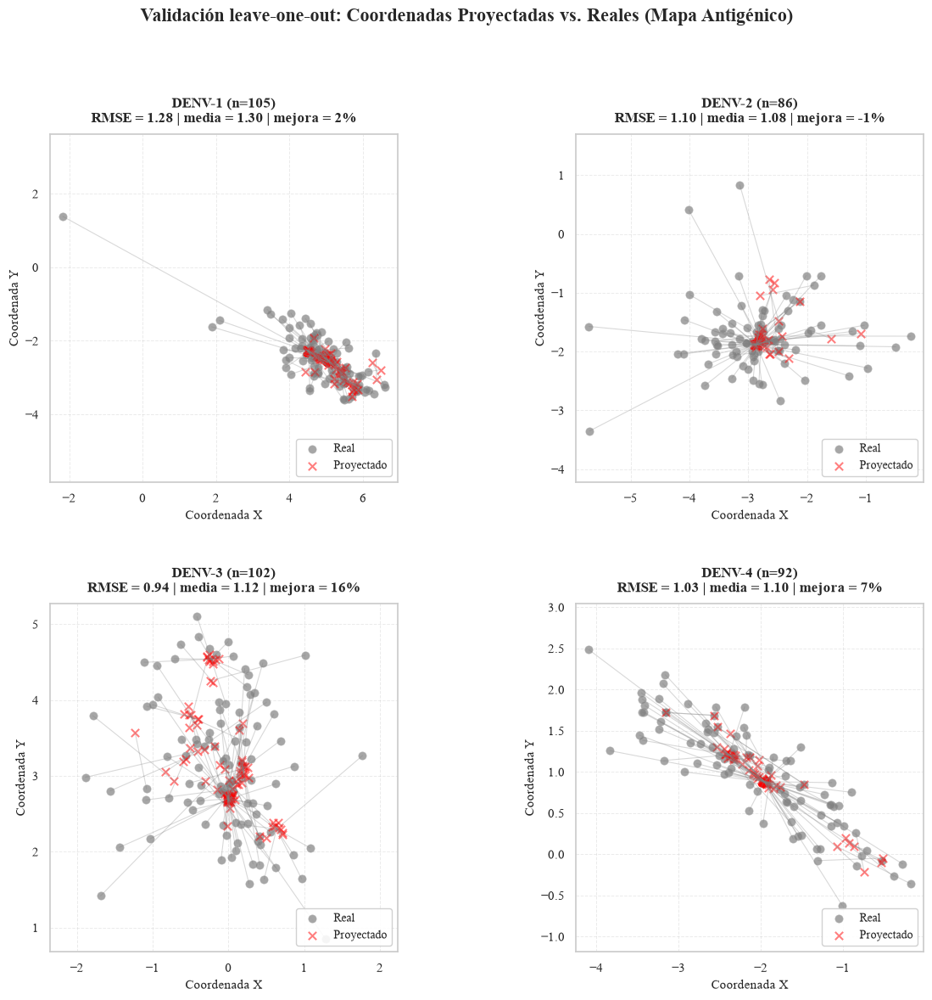

In [38]:
# 1) Validación leave-one-out (reemplaza project_strains_self)
base = validate_loo(df_matrices_val, mapa_ag)

# 2) Mismo formato que antes: validation_results[sero] con error_X, error_Y, euclidean_error
validation_results = {}
for sero in [1, 2, 3, 4]:
    df_val = base[sero].reset_index()          # strainID vuelve a ser columna
    df_val['error_X'] = df_val['proj_X'] - df_val['real_X']
    df_val['error_Y'] = df_val['proj_Y'] - df_val['real_Y']
    df_val['euclidean_error'] = np.sqrt(df_val['error_X']**2 + df_val['error_Y']**2)
    # error de la línea base (media del serotipo sin la propia cepa)
    df_val['euclidean_error_media'] = np.sqrt((df_val['mean_X'] - df_val['real_X'])**2 +
                                              (df_val['mean_Y'] - df_val['real_Y'])**2)
    validation_results[sero] = df_val

# 3) Tabla resumen
summary_rows = []
for sero in [1, 2, 3, 4]:
    df_val = validation_results[sero]
    r_x, p_x = stats.pearsonr(df_val['real_X'], df_val['proj_X'])
    r_y, p_y = stats.pearsonr(df_val['real_Y'], df_val['proj_Y'])

    ss_res_x = np.sum(df_val['error_X']**2)
    ss_tot_x = np.sum((df_val['real_X'] - df_val['real_X'].mean())**2)
    r2_x = 1 - ss_res_x / ss_tot_x if ss_tot_x > 0 else 0

    ss_res_y = np.sum(df_val['error_Y']**2)
    ss_tot_y = np.sum((df_val['real_Y'] - df_val['real_Y'].mean())**2)
    r2_y = 1 - ss_res_y / ss_tot_y if ss_tot_y > 0 else 0

    rmse = np.sqrt(np.mean(df_val['euclidean_error']**2))
    rmse_media = np.sqrt(np.mean(df_val['euclidean_error_media']**2))

    summary_rows.append({
        'Serotipo': f'DENV-{sero}',
        'n': len(df_val),
        'r_X': round(r_x, 4), 'p_X': f'{p_x:.2e}',
        'r_Y': round(r_y, 4), 'p_Y': f'{p_y:.2e}',
        'R²_X': round(r2_x, 4), 'R²_Y': round(r2_y, 4),
        'RMSE': round(rmse, 4),
        'RMSE_media': round(rmse_media, 4),
        'Mejora_vs_media': round(1 - rmse / rmse_media, 4),
        'MAE': round(df_val['euclidean_error'].mean(), 4),
        'Mediana Error': round(df_val['euclidean_error'].median(), 4)
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.to_string(index=False))

# 4) Figura: paneles cuadrados, con RMSE y mejora vs. media en cada título
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, sero in enumerate([1, 2, 3, 4]):
    df_val = validation_results[sero]
    ax = axes[idx]
    row = df_summary.iloc[idx]

    for i in range(len(df_val)):
        ax.plot([df_val.iloc[i]['real_X'], df_val.iloc[i]['proj_X']],
                [df_val.iloc[i]['real_Y'], df_val.iloc[i]['proj_Y']],
                color='gray', alpha=0.3, linewidth=0.8)

    ax.scatter(df_val['real_X'], df_val['real_Y'], alpha=0.7, s=45,
               c='grey', label='Real', marker='o', edgecolors='darkgrey', linewidth=0.5)
    ax.scatter(df_val['proj_X'], df_val['proj_Y'], alpha=0.5, s=45,
               c='red', label='Proyectado', marker='x', linewidth=1.5)

    all_x = np.concatenate([df_val['real_X'], df_val['proj_X']])
    all_y = np.concatenate([df_val['real_Y'], df_val['proj_Y']])
    cx, cy = (all_x.min() + all_x.max()) / 2, (all_y.min() + all_y.max()) / 2
    half = max(all_x.max() - all_x.min(), all_y.max() - all_y.min()) / 2 * 1.08
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    ax.set_box_aspect(1)
    ax.set_aspect('equal')

    ax.set_title(f'DENV-{sero} (n={row["n"]})\n'
                 f'RMSE = {row["RMSE"]:.2f} | media = {row["RMSE_media"]:.2f} | '
                 f'mejora = {row["Mejora_vs_media"]*100:.0f}%',
                 fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Coordenada X', fontsize=11)
    ax.set_ylabel('Coordenada Y', fontsize=11)
    ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
    ax.grid(alpha=0.4, linestyle='--', linewidth=0.7)

plt.suptitle('Validación leave-one-out: Coordenadas Proyectadas vs. Reales (Mapa Antigénico)',
             fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.subplots_adjust(hspace=0.35, wspace=0.25)
plt.savefig('../figures/validation_projected_vs_real.png', dpi=300, bbox_inches='tight')
plt.show()

In [44]:
import glob
from scipy.spatial import procrustes

def read_final(p):
    rows=[l.split() for l in open(p) if l.startswith("AG")]
    return pd.DataFrame({"id":[r[1] for r in rows],"x":[float(r[2]) for r in rows],"y":[float(r[3]) for r in rows]}).set_index("id")

def read_layout(p):
    rows=[l.split() for l in open(p) if l.startswith("AG")]
    return pd.DataFrame({"id":[r[2] for r in rows],"x":[float(r[3]) for r in rows],"y":[float(r[4]) for r in rows]}).set_index("id")

def align(A,B):
    """Rota/refleja/traslada A sobre B (sin escala)."""
    ca,cb=A.mean(0),B.mean(0); A0,B0=A-ca,B-cb
    U,S,Vt=np.linalg.svd(A0.T@B0); R=U@Vt
    return A0@R+cb

final=read_final("../resources/experimental_data/2d-antigenic-map.txt")
ids=final.index
F=final.values
sero=np.array([i.split("/")[0] for i in ids])

devs=[]; aligned=[]
for p in sorted(glob.glob("../resources/experimental_data/D2/pred-*-layout.txt")):
    L=read_layout(p).reindex(ids)
    assert L.notna().all().all()
    A=align(L.values,F); aligned.append(A)
    devs.append(np.linalg.norm(A-F,axis=1))
aligned=np.array(aligned); devs=np.array(devs)      # (100, 412)
print("mapas:",devs.shape)

# desviación por cepa respecto al mapa final y entre mapas (a la media alineada)
rms_final=np.sqrt((devs**2).mean(0))
M=aligned.mean(0)
rms_mean=np.sqrt(((aligned-M)**2).sum(2).mean(0))

ids_val = pd.read_csv("../output/ids_385_validadas.csv")["strainID"].astype(str)
en_val = ids.isin(ids_val)                       # máscara sobre las 412 cepas del mapa
print("validadas halladas en el mapa:", en_val.sum(), "de", len(ids_val))   # debe dar 385 de 385

res = []
for s in ["DENV1", "DENV2", "DENV3", "DENV4"]:
    m = (sero == s) & en_val                     # <- solo cepas del serotipo con secuencia
    sd_ser = np.sqrt(((F[m] - F[m].mean(0))**2).sum(1).mean())
    res.append(dict(Serotipo=s, n=m.sum(),
        ruido_RMS_vs_final=np.sqrt((devs[:, m]**2).mean()),
        ruido_mediana_cepa=np.median(rms_final[m]),
        ruido_p90_cepa=np.percentile(rms_final[m], 90),
        dispersion_serotipo_RMSE_media=sd_ser))
r = pd.DataFrame(res).round(3); print(r.to_string(index=False))
r["ratio"] = (r.ruido_RMS_vs_final / r.dispersion_serotipo_RMSE_media).round(3)
print(r[["Serotipo", "ratio"]].to_string(index=False))

top = pd.Series(rms_final, index=ids)[en_val].sort_values(ascending=False).head(8)
print(top.round(2))

mapas: (100, 412)
validadas halladas en el mapa: 385 de 385
Serotipo   n  ruido_RMS_vs_final  ruido_mediana_cepa  ruido_p90_cepa  dispersion_serotipo_RMSE_media
   DENV1 105               0.828               0.507           1.086                           1.285
   DENV2  86               0.941               0.640           1.162                           1.072
   DENV3 102               0.858               0.597           1.309                           1.109
   DENV4  92               0.966               0.521           1.614                           1.092
Serotipo  ratio
   DENV1  0.644
   DENV2  0.878
   DENV3  0.774
   DENV4  0.885
id
DENV1/CAMBODIA/2003/FJ639680      4.18
DENV4/THAILAND/2010/00780/10      3.94
DENV2/CAMBODIA/2008/GQ868638      3.51
DENV3/THAILAND/2006/02121/06      3.22
DENV4/THAILAND/2011/00257/11      2.88
DENV1/PUERTORICO/2006/BID-V852    2.61
DENV4/THAILAND/2013/00691/13      2.56
DENV2/THAILAND/2006/00127/06      2.50
dtype: float64


# probando Graham sobre todo gen E

In [60]:
cols = df_matrices_val[0].columns.tolist()

df_val_full = []
for s in range(4):
    ids = df_matrices_val[s].index.tolist()
    D = np.array([[dist_full_E(seq_al[i], seq_al[c]) for c in cols] for i in ids], dtype=float)
    df_val_full.append(pd.DataFrame(D, index=ids, columns=cols))

res_full = validate_loo(df_val_full, mapa_ag)
print(resumen(res_full))

  Serotipo    n     r_X     r_Y  RMSE_proy  RMSE_media  RMSE_vecino  \
0   DENV-1  105  0.1564  0.1655     1.3203      1.2977       4.2421   
1   DENV-2   86  0.0161  0.2993     1.1224      1.0848       1.2412   
2   DENV-3  102  0.1890  0.6783     0.9366      1.1197       1.0555   
3   DENV-4   92  0.3255  0.2839     1.0845      1.1038       1.3251   

   skill_vs_media  
0         -0.0174  
1         -0.0346  
2          0.1636  
3          0.0175  


# probando Hamming sobre epitopos

In [61]:
cols = df_matrices_val[0].columns.tolist()

def build_matrix(df_ref, sero, metric):
    ids = df_ref.index.tolist()
    D = np.array([[antigenic_distance(seqs[i], seqs[c], sero, type=metric) for c in cols]
                  for i in ids], dtype=float)
    return pd.DataFrame(D, index=ids, columns=cols)

df_h = [build_matrix(df_matrices_val[s], s + 1, 'hamming') for s in range(4)]
print(resumen(validate_loo(df_h, mapa_ag)))

  Serotipo    n     r_X     r_Y  RMSE_proy  RMSE_media  RMSE_vecino  \
0   DENV-1  105  0.2357  0.1433     1.2889      1.2977       4.8372   
1   DENV-2   86  0.0266  0.2089     1.1001      1.0848       1.1869   
2   DENV-3  102  0.3857  0.6105     0.9372      1.1197       1.1376   
3   DENV-4   92  0.3485  0.4065     1.0271      1.1038       1.2324   

   skill_vs_media  
0          0.0068  
1         -0.0141  
2          0.1630  
3          0.0694  


# Transmission Dynamics


Cargando árbol DENV-1

Cargando árbol DENV-2

Cargando árbol DENV-3

Cargando árbol DENV-4


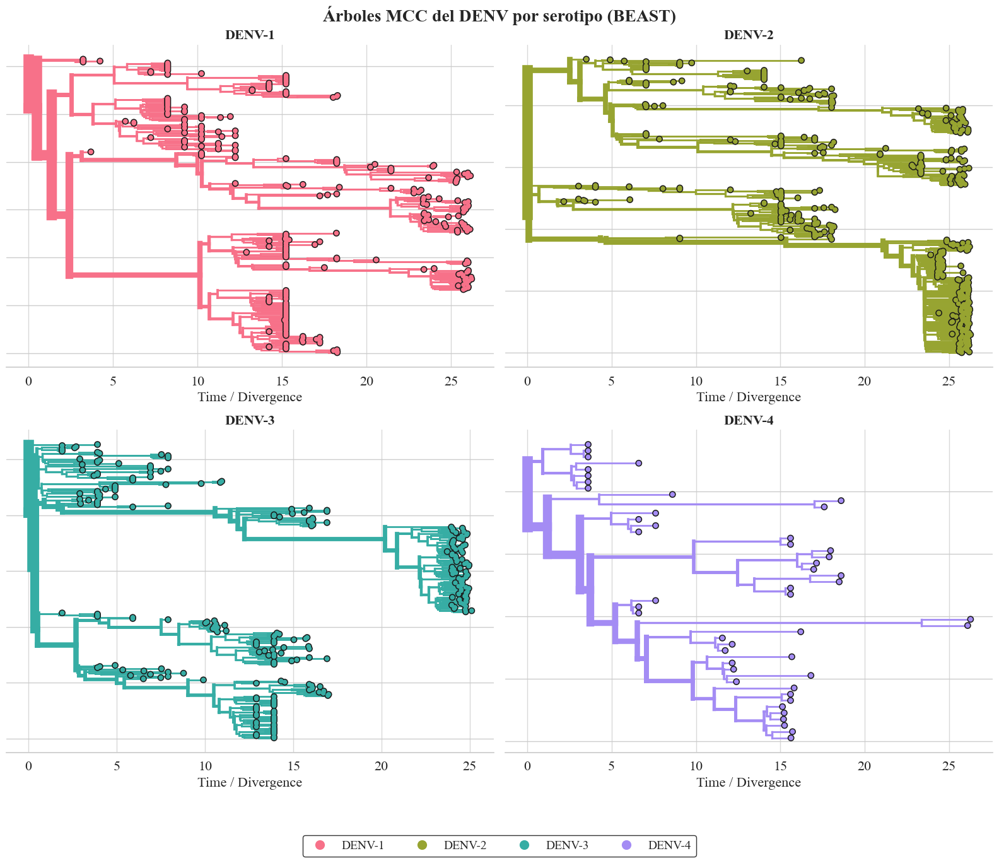


Figura guardada en: ../figures/DENV_beast_trees_husl.jpeg


In [71]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib.pyplot as plt
import baltic as bt
import seaborn as sns
from matplotlib.lines import Line2D
import re

plt.rcParams["font.family"] = "Times New Roman"

# ============================================================
# CONFIGURACIÓN
# ============================================================
TREE_FILES = {
    1: "../resources/BEAST/DENV1_BDSKY_MCC.tree",
    2: "../resources/BEAST/DENV2_BDSKY_MCC.tree",
    3: "../resources/BEAST/DENV3_BDSKY_MCC.tree",
    4: "../resources/BEAST/DENV4_BDSKY_MCC.tree",
}

OUTPUT_FILE = "../figures/DENV_beast_trees_husl.jpeg"

# Paleta de colores HUSL (4 colores distintos)
# baltic/matplotlib acepta directamente las tuplas RGB
COLORS = sns.husl_palette(4)

# ============================================================
# FUNCIONES AUXILIARES
# ============================================================
def load_beast_tree(tree_path):
    """
    Carga un archivo .tree de BEAST/TreeAnnotator.
    """
    ll = bt.loadNewick(tree_path, absoluteTime=False)
    return ll


# ============================================================
# CREAR FIGURA 2x2
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, sero in enumerate([1, 2, 3, 4]):
    ax = axes[idx]
    color = COLORS[idx]
    
    print(f"\n{'='*50}")
    print(f"Cargando árbol DENV-{sero}")
    print(f"{'='*50}")
    
    # Cargar árbol
    ll = load_beast_tree(TREE_FILES[sero])
    
    # Función de color: todo del mismo color
    def c_func(k, color=color):
        return color
    
    # Grosor de ramas proporcional al número de hojas descendientes
    L = sum(1 for k in ll.Objects if k.branchType == "leaf")
    b_func = lambda k: (
        2 + 10.0 * len(k.leaves) / L
        if k.branchType == "node"
        else 2
    )
    
    # Graficar árbol
    ll.plotTree(ax, width=b_func, colour=c_func, zorder=20000)
    ll.plotPoints(ax, size=30, colour=c_func, zorder=20002)
    
    # Estética
    for loc in ["left", "right", "top"]:
        ax.spines[loc].set_visible(False)
    
    ax.grid(axis="x", ls="-", color="grey", alpha=0.3)
    ax.tick_params(axis="y", size=0)
    ax.tick_params(axis="x", labelsize=16)
    ax.set_xlabel("Time / Divergence", fontsize=16)
    ax.set_yticklabels([])
    ax.set_title(f"DENV-{sero}", fontsize=16, fontweight="bold")

# ============================================================
# TÍTULO Y LEYENDA
# ============================================================
fig.suptitle(
    "Árboles MCC del DENV por serotipo (BEAST)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# Leyenda con los colores HUSL
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=f"DENV-{sero}",
        markerfacecolor=COLORS[idx],
        markersize=12
    )
    for idx, sero in enumerate([1, 2, 3, 4])
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    fontsize=14,
    frameon=True,
    edgecolor="black",
    ncol=4
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nFigura guardada en: {OUTPUT_FILE}")

In [ ]:
# 1. Leer el árbol en formato NEXUS
archivo = "archivo.tree"
arbol = Phylo.read(archivo, "nexus")

# 2. Obtener los nombres de los taxones (hojas)
taxones = [hoja.name for hoja in arbol.get_terminals()]

# 3. Crear una matriz de distancias inicializada en cero
matriz = pd.DataFrame(
    0.0,
    index=taxones,
    columns=taxones
)

# 4. Calcular las distancias patristicas
for taxon1, taxon2 in combinations(taxones, 2):
    distancia = arbol.distance(taxon1, taxon2)

    matriz.loc[taxon1, taxon2] = distancia
    matriz.loc[taxon2, taxon1] = distancia

# 5. Guardar la matriz de distancias
matriz.to_csv("matriz_distancias.csv", encoding="utf-8")
matriz.to_excel("matriz_distancias.xlsx")

# 6. Mostrar la matriz
print(matriz)


In [26]:
mapa_ag

,type,strainID,coord1,coord2,sero_num,sero
0,AG,DENV1/BOLIVIA/2010/FSB-3363,6.353862,-2.327160,1,DENV1
1,AG,DENV1/CAMBODIA/2003/FJ639680,-2.168056,1.380308,1,DENV1
2,AG,DENV1/CAMBODIA/2003/GQ868619,6.035595,-3.399189,1,DENV1
3,AG,DENV1/CAMBODIA/2006/FJ639687,5.507046,-3.134495,1,DENV1
4,AG,DENV1/CAMBODIA/2007/FJ639693,5.382380,-2.959874,1,DENV1
...,...,...,...,...,...,...
443,SR,DEN3_NICARAGUA_2009_608,-1.281476,2.457215,3,DENV3
444,SR,DEN3_PUERTORICO_1963_PRS_228762,-1.919125,2.494553,3,DENV3
445,SR,DEN4_MALAYSIA_1973_P73_1120_SYLVATIC,-1.444320,1.851395,4,DENV4
446,SR,DEN4_BURMA_2008_81087,-2.757915,1.077952,4,DENV4


DENV1: 10 linajes
DENV1: 308 hojas | 304 con coordenadas
   sin emparejar (ejemplos): ['hDenV1/Colombia/BOL-UEB-016-1/2019', 'hDenV1/Colombia/BOL-UEB-016/2019', 'hDenV1/Colombia/BOL-UEB-152-1/2019', 'hDenV1/Colombia/BOL-UEB-152/2019']
   con grupo asignado: 304 de 304 | 10 categorías


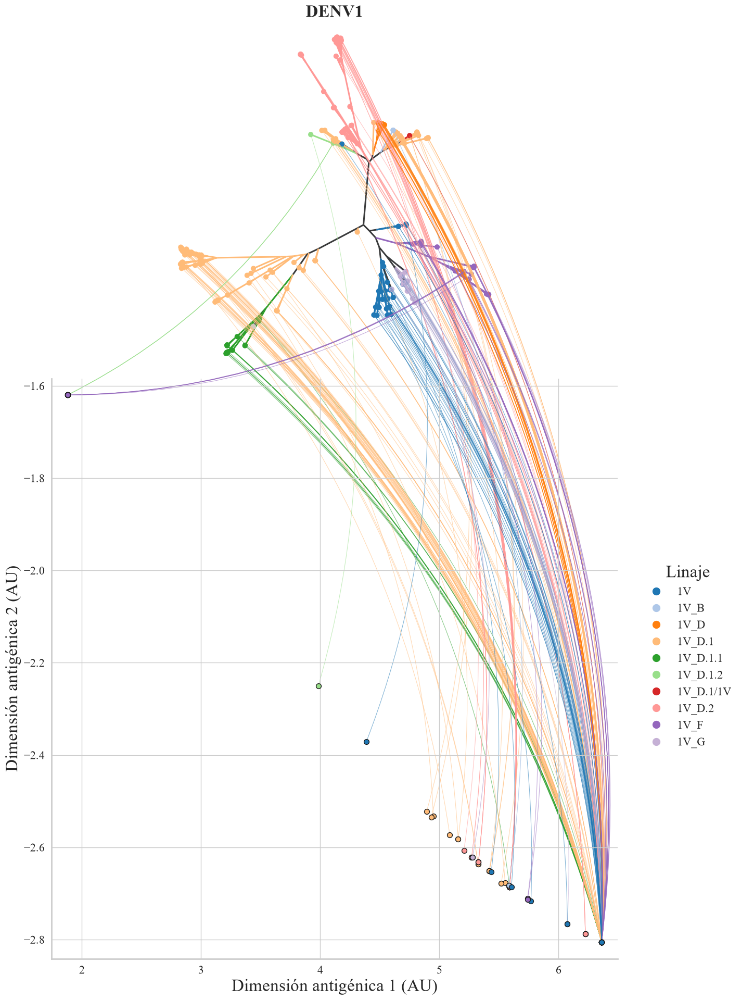

DENV2: 10 linajes
DENV2: 475 hojas | 467 con coordenadas
   sin emparejar (ejemplos): ['hDenV2/Colombia/BOL-UEB-121/2019', 'hDenV2/Colombia/BOL-UEB-125/2019', 'hDenV2/Colombia/BOL-UEB-130/2021', 'hDenV2/Colombia/BOL-UEB-98/2021', 'hDenV2/Colombia/BOL-UEB-15/2021']
   con grupo asignado: 467 de 467 | 9 categorías


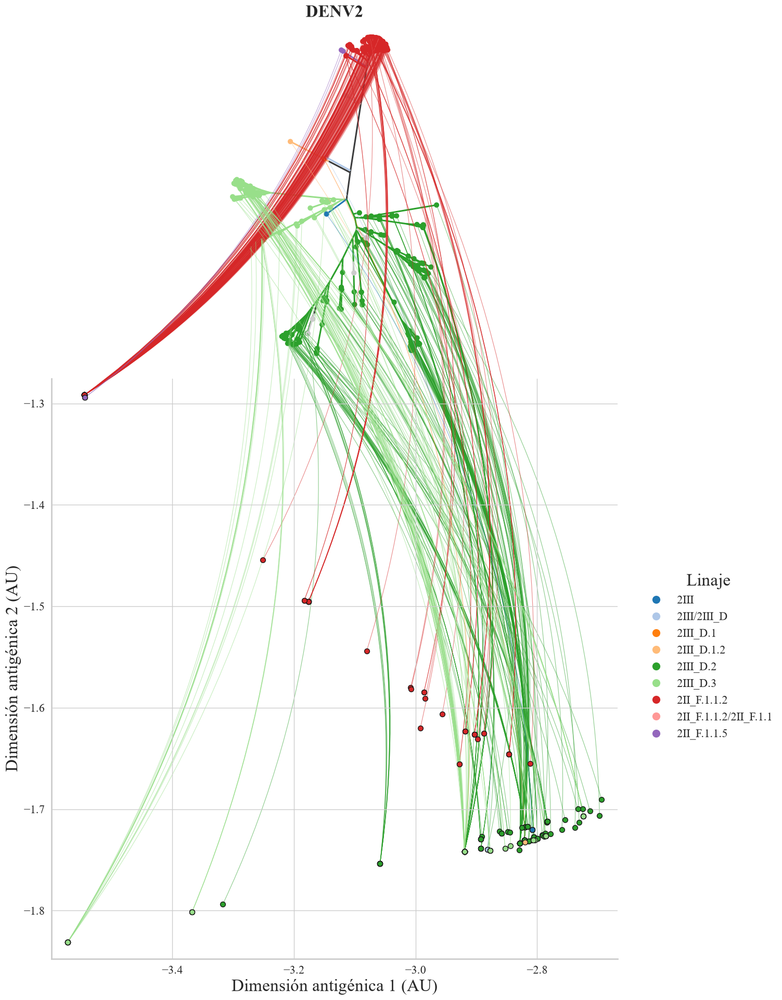

DENV3: 2 linajes
DENV3: 264 hojas | 261 con coordenadas
   sin emparejar (ejemplos): ['hDenV3/Colombia/SAN-UIS-0000037/2015', 'hDenV3/Colombia/SAN-UIS-0000010/2015', 'hDenV3/Colombia/VID-UEB-010/2023']
   con grupo asignado: 261 de 261 | 2 categorías


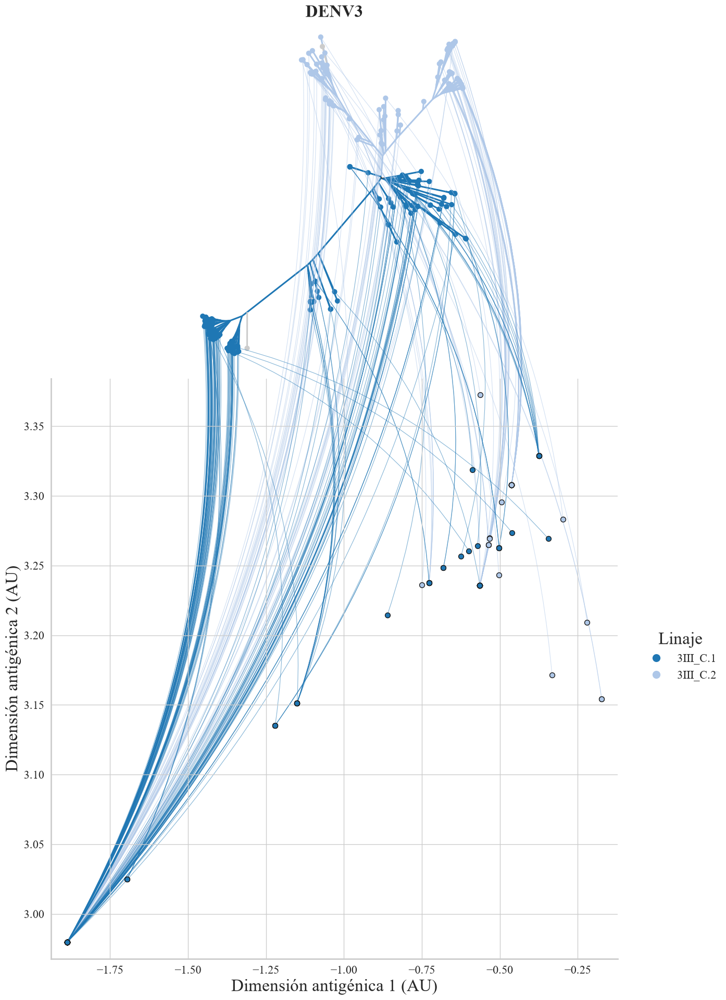

DENV4: 5 linajes
DENV4: 48 hojas | 48 con coordenadas
   con grupo asignado: 48 de 48 | 5 categorías


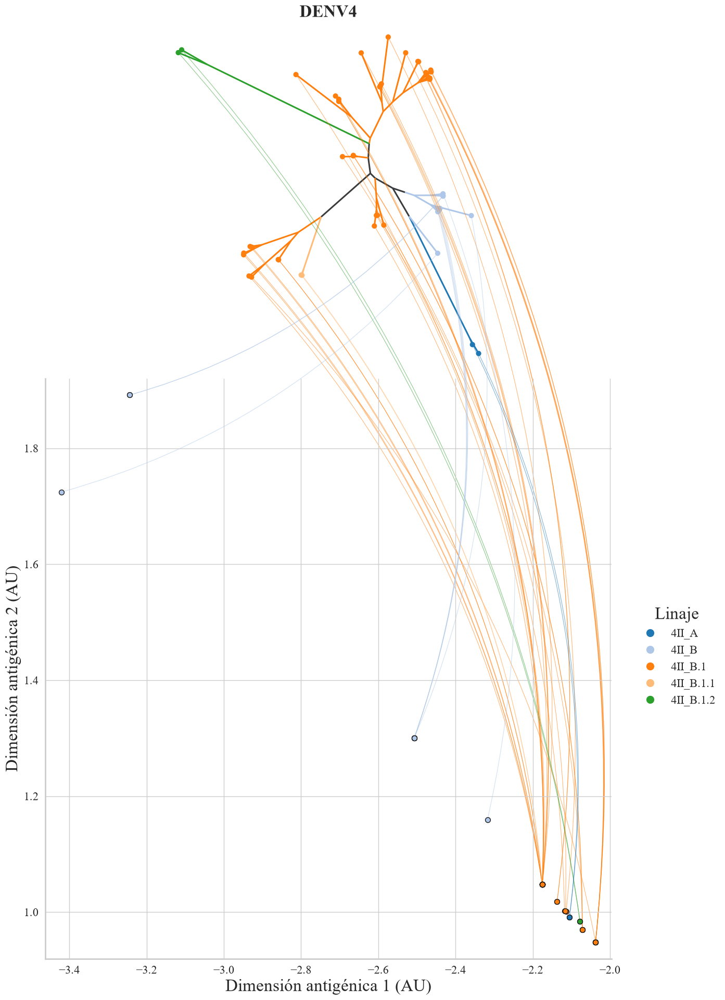

In [22]:
import io, re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D
from Bio import Phylo

sys.setrecursionlimit(10000)
GREY = "#999999"


# ───────────── 1) Leer el árbol MCC de BEAST (.tree, Nexus) ─────────────
def load_mcc(path):
    """Lee un árbol en Nexus (MCC de BEAST) o en Newick (.nwk, p. ej. ML).
    En Nexus aplica el bloque translate; en ambos casos elimina las anotaciones [&...]."""
    txt = open(path).read().replace("\r", "")
    trans = {}
    if "#nexus" in txt.lower():
        m = re.search(r"translate\s+(.*?);", txt, re.S | re.I)
        if m:
            for part in m.group(1).split(","):
                part = part.strip()
                if part:
                    k, v = part.split(None, 1)
                    trans[k] = v.strip().strip("'\"")
        tree_str = re.search(r"^\s*tree\s+[^=]+=\s*(.*?;)", txt, re.S | re.I | re.M).group(1)
    else:
        tree_str = txt.strip().split(";")[0] + ";"
    tree_str = re.sub(r"\[&[^\]]*\]", "", tree_str)
    tree = Phylo.read(io.StringIO(tree_str), "newick")
    for t in tree.get_terminals():
        t.name = trans.get(t.name, t.name).strip("'\"")
    return tree


def prune_to(tree, keep):
    """Deja solo las hojas cuyo nombre está en 'keep'; colapsa los nodos que quedan con un solo hijo
    sumando las longitudes de rama."""
    def rec(cl):
        if cl.is_terminal():
            return cl if cl.name in keep else None
        kids = [k for k in (rec(c) for c in cl.clades) if k is not None]
        if not kids:
            return None
        if len(kids) == 1:
            k = kids[0]; k.branch_length = (k.branch_length or 0.0) + (cl.branch_length or 0.0)
            return k
        cl.clades = kids
        return cl
    tree.root = rec(tree.root)
    return tree


def match_ids(tip_names, ids):
    """Empareja el nombre de cada hoja con el ID de la cepa (exacto, sin fecha tras '|', o sin distinguir mayúsculas)."""
    ids = set(ids); low = {i.lower(): i for i in ids}; out = {}
    for t in tip_names:
        for c in (t, t.split("|")[0], t.split("|")[0].replace("_", " ")):
            if c in ids:
                out[t] = c; break
            if c.lower() in low:
                out[t] = low[c.lower()]; break
    return out


# ───────────── 2) Distribución sin raíz (equal-angle) y datos por nodo ─────────────
def unrooted_layout(tree, rotate=0.2):
    """Coloca cada nodo del árbol en el plano. Devuelve:
       edges: lista de (clado_padre, clado_hijo, (x0,y0), (x1,y1)); pos: id(clado) -> (x,y)"""
    n_leaves = {}
    def count(cl):
        n_leaves[id(cl)] = 1 if cl.is_terminal() else sum(count(c) for c in cl.clades)
        return n_leaves[id(cl)]
    count(tree.root)

    pos, edges = {}, []
    def rec(cl, x, y, a0, a1):
        pos[id(cl)] = (x, y)
        ang = a0
        for ch in sorted(cl.clades, key=lambda c: -n_leaves[id(c)]):
            span = (a1 - a0) * n_leaves[id(ch)] / n_leaves[id(cl)]
            mid = ang + span / 2
            L = ch.branch_length or 0.0
            cx, cy = x + L * np.cos(mid), y + L * np.sin(mid)
            edges.append((cl, ch, (x, y), (cx, cy)))
            rec(ch, cx, cy, ang, ang + span)
            ang += span
    rec(tree.root, 0.0, 0.0, rotate, rotate + 2 * np.pi)
    return edges, pos


def leaf_sets(tree):
    """id(clado) -> conjunto de nombres de hojas descendientes."""
    out = {}
    def rec(cl):
        out[id(cl)] = {cl.name} if cl.is_terminal() else set().union(*(rec(c) for c in cl.clades))
        return out[id(cl)]
    rec(tree.root)
    return out


# ───────────── 3) Aristas del árbol sobre el espacio antigénico ─────────────
def phylo_segments(tree, xy, grp, gcol):
    """Cada nodo interno se ubica en el promedio de las coordenadas proyectadas de sus hojas
    descendientes; se traza padre -> hijo. xy y grp están indexados por nombre de hoja."""
    segs, cols = [], []
    def rec(cl):
        if cl.is_terminal():
            if cl.name in xy:
                return [xy[cl.name]], {grp.get(cl.name)}, xy[cl.name]
            return [], set(), None
        pts, gs, hijos = [], set(), []
        for ch in cl.clades:
            p, g, pos = rec(ch)
            pts += p; gs |= g
            hijos.append((pos, g))
        pos = np.mean(pts, axis=0) if pts else None
        for pos_h, g_h in hijos:
            if pos is not None and pos_h is not None:
                segs.append([pos, pos_h])
                cols.append(gcol.get(next(iter(g_h)), GREY) if len(g_h) == 1 else GREY)
        return pts, gs, pos
    rec(tree.root)
    return segs, cols


# ───────────── 4) Figura: árbol arriba, mapa de las proyectadas abajo ─────────────
def plot_tree_map(tree_file, proj, sero, groups, ref_xy=None, connect="tips",
                  out=None, rotate=0.2, group_title="Genotipo",
                  prune_unmatched=False, title=None):
    """
    tree_file : MCC de BEAST (.tree, Nexus) de ese serotipo
    proj      : DataFrame con columnas X, Y indexado por strainID (projected_coordinates[sero])
    groups    : Series strainID -> genotipo/clado (define los colores, como el clado en tu t-SNE)
    ref_xy    : DataFrame opcional con coord1, coord2 de las referencias (fondo gris claro)
    connect   : "tips"  -> línea curva de cada hoja del árbol a su punto en el mapa (como tu figura original)
                "phylo" -> además/en vez de eso, las aristas del árbol dibujadas sobre el mapa
                "both"
    """
    tree = load_mcc(tree_file)
    tips = [t.name for t in tree.get_terminals()]
    nm2id = match_ids(tips, proj.index)
    print(f"DENV{sero}: {len(tips)} hojas | {len(nm2id)} con coordenadas")
    if prune_unmatched and len(nm2id) < len(tips):       # árbol más grande que el mapa: dejar solo lo que tiene coordenadas
        tree = prune_to(tree, set(nm2id))
        tips = [t.name for t in tree.get_terminals()]
        print(f"   árbol podado a {len(tips)} hojas")
    if len(nm2id) < len(tips):
        print("   sin emparejar (ejemplos):", [t for t in tips if t not in nm2id][:5])

    xy = {t: proj.loc[i, ["X", "Y"]].values.astype(float) for t, i in nm2id.items()}
    groups = groups.dropna().astype(str)                 # acepta linajes numéricos o con vacíos
    grp = {t: groups.get(i) for t, i in nm2id.items()}
    print(f"   con grupo asignado: {sum(v is not None for v in grp.values())} de {len(grp)} | "
          f"{len(set(v for v in grp.values() if v is not None))} categorías")
    cats = sorted({g for g in grp.values() if isinstance(g, str)})
    pal = plt.get_cmap("tab20")
    gcol = {g: mcolors.to_hex(pal(i % 20)) for i, g in enumerate(cats)}
    color_of = lambda name: gcol.get(grp.get(name), "#CCCCCC")

    fig = plt.figure(figsize=(16, 20), facecolor="w")
    gs = gridspec.GridSpec(2, 1, height_ratios=[0.6, 1], hspace=0.02,
                           left=0.08, right=0.76, top=0.96, bottom=0.06)   # deja el 24% derecho para la leyenda
    ax_tree, ax_map = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    # --- árbol sin raíz, ramas coloreadas por grupo
    edges, pos = unrooted_layout(tree, rotate)
    leaves = leaf_sets(tree)

    def c_clade(cl):
        if cl.is_terminal():
            return color_of(cl.name)
        g = {grp.get(h) for h in leaves[id(cl)] if h in xy}
        return gcol.get(next(iter(g)), "#3A3B3C") if len(g) == 1 else "#3A3B3C"

    ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                           colors=[c_clade(e[1]) for e in edges], linewidths=2.2, zorder=10))
    leaf_xy = {t.name: pos[id(t)] for t in tree.get_terminals()}
    ax_tree.scatter([p[0] for p in leaf_xy.values()], [p[1] for p in leaf_xy.values()],
                    c=[color_of(n) for n in leaf_xy], s=40, zorder=20)
    ax_tree.autoscale_view(); ax_tree.set_aspect("equal", adjustable="datalim")
    for sp in ax_tree.spines.values(): sp.set_visible(False)
    ax_tree.set_xticks([]); ax_tree.set_yticks([])

    # --- mapa antigénico de las cepas proyectadas
    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=18, c="#e3e3e3", zorder=0)
    if connect in ("phylo", "both"):
        segs, cols = phylo_segments(tree, xy, grp, gcol)
        ax_map.add_collection(LineCollection(segs, colors=cols, linewidths=0.8, alpha=0.5, zorder=1))
    for name, p in xy.items():
        ax_map.scatter(*p, c=color_of(name), edgecolor="k", s=50, alpha=1, zorder=3)

    # --- conexión hoja del árbol -> punto en el mapa (mismo color), como en tu t-SNE
    if connect in ("tips", "both"):
        for name, p in xy.items():
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(p), coordsA=ax_map.transData,
                xyB=leaf_xy[name], coordsB=ax_tree.transData,
                linestyle="-", color=color_of(name), linewidth=0.8, alpha=0.55,
                connectionstyle="arc3,rad=0.15", zorder=0))

    ax_map.margins(x=0.03, y=0.03)
    ax_map.set_xlabel("Dimensión antigénica 1 (AU)", fontsize=24)
    ax_map.set_ylabel("Dimensión antigénica 2 (AU)", fontsize=24)
    ax_map.tick_params(axis="both", labelsize=16)
    for sp in ("right", "top"): ax_map.spines[sp].set_visible(False)
    for sp in ax_map.spines.values(): sp.set_linewidth(2)

    handles = [Line2D([0], [0], marker="o", color="w", label=g, markerfacecolor=gcol[g],
                      markersize=8) for g in cats if g in set(grp.values())]
    fig.legend(handles=handles, title=group_title, loc="center left",
               bbox_to_anchor=(0.78, 0.35), frameon=False,
               fontsize=16, title_fontsize=24, markerscale=1.5)      # en coordenadas de la figura
    ax_tree.set_title(title or f"DENV{sero}", fontsize=24, fontweight="bold")
    if out:
        plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()


# ───────────── Uso ─────────────
def lineage_series(meta_template, sero):
    meta = pd.read_csv(meta_template.format(sero), sep="\t")
    key = "strain" if "strain" in meta.columns else meta.columns[0]   # misma regla que en compute_grantham_matrices
    return meta.drop_duplicates(key).set_index(key)["lineage"]
projected_coordinates = project_strains(df_matrices, mapa_ag)
for sero in [1, 2, 3, 4]:
    groups = lineage_series(META_CLEAN_COL, sero)
    print(f"DENV{sero}: {groups.nunique()} linajes")
    plot_tree_map(f"../resources/BEAST/DENV{sero}_BDSKY_MCC.tree",
                  projected_coordinates[sero], sero,
                  groups=groups, group_title="Linaje",
                  out=f"../figures/arbol_mapa_DENV{sero}.png")

DENV1: 308 hojas | 304 con coordenadas proyectadas
   Mantel (spearman): r = 0.077, p = 0.0120 | pares = 46056
DENV2: 475 hojas | 467 con coordenadas proyectadas
   Mantel (spearman): r = 0.606, p = 0.0010 | pares = 108811
DENV3: 264 hojas | 261 con coordenadas proyectadas
   Mantel (spearman): r = 0.224, p = 0.0010 | pares = 33930
DENV4: 48 hojas | 48 con coordenadas proyectadas
   Mantel (spearman): r = 0.064, p = 0.2230 | pares = 1128
   serotype  n_tips  n_pairs       r      p    method
0         1     304    46056  0.0775  0.012  spearman
1         2     467   108811  0.6063  0.001  spearman
2         3     261    33930  0.2238  0.001  spearman
3         4      48     1128  0.0642  0.223  spearman


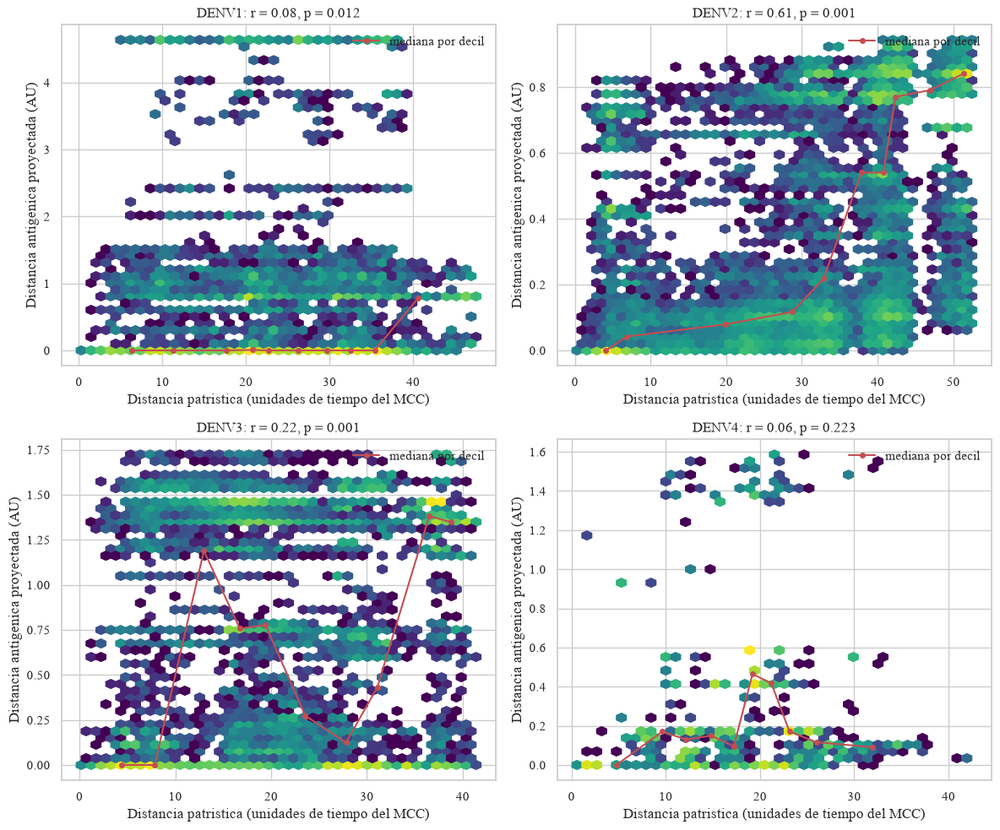

In [23]:
import io, re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr, rankdata
from Bio import Phylo

sys.setrecursionlimit(10000)


# ───────────── Lectura del MCC y emparejamiento (igual que en arbol_mapa_antigenico.py) ─────────────
def load_mcc(path):
    txt = open(path).read()
    trans = {}
    m = re.search(r"translate\s+(.*?);", txt, re.S | re.I)
    if m:
        for part in m.group(1).split(","):
            part = part.strip()
            if part:
                k, v = part.split(None, 1)
                trans[k] = v.strip().strip("'\"")
    tree_str = re.search(r"^\s*tree\s+[^=]+=\s*(.*?;)", txt, re.S | re.I | re.M).group(1)
    tree_str = re.sub(r"\[&[^\]]*\]", "", tree_str)
    tree = Phylo.read(io.StringIO(tree_str), "newick")
    for t in tree.get_terminals():
        t.name = trans.get(t.name, t.name).strip("'\"")
    return tree


def match_ids(tip_names, ids):
    ids = set(ids); out = {}
    for t in tip_names:
        for c in (t, t.split("|")[0], t.split("|")[0].replace("_", " ")):
            if c in ids:
                out[t] = c; break
    return out


# ───────────── Distancia patristica ─────────────
def patristic_matrix(tree):
    """Matriz de distancias patristicas (suma de longitudes de rama) entre todas las hojas.
    Devuelve (nombres de hojas, matriz N x N)."""
    tips = tree.get_terminals()
    idx = {id(t): i for i, t in enumerate(tips)}
    n = len(tips)
    D = np.zeros((n, n))
    depth = {}
    def set_depth(cl, d):
        depth[id(cl)] = d
        for ch in cl.clades:
            set_depth(ch, d + (ch.branch_length or 0.0))
    set_depth(tree.root, 0.0)

    def rec(cl):
        if cl.is_terminal():
            return [idx[id(cl)]]
        groups = [rec(ch) for ch in cl.clades]
        dn = depth[id(cl)]
        dep = np.array([depth[id(t)] for t in tips])
        for a in range(len(groups)):
            for b in range(a + 1, len(groups)):
                La, Lb = groups[a], groups[b]
                block = dep[La][:, None] + dep[Lb][None, :] - 2 * dn
                D[np.ix_(La, Lb)] = block
                D[np.ix_(Lb, La)] = block.T
        return [i for g in groups for i in g]
    rec(tree.root)
    return [t.name for t in tips], D


# ───────────── Prueba de Mantel ─────────────
def mantel(A, B, method="spearman", perms=999, seed=0):
    """Correlacion entre dos matrices de distancias y valor p por permutacion de las etiquetas
    (las distancias por pares no son independientes, asi que un p de Pearson/Spearman seria enganoso)."""
    n = A.shape[0]
    iu = np.triu_indices(n, 1)
    a = A[iu]
    corr = (lambda x, y: spearmanr(x, y)[0]) if method == "spearman" else (lambda x, y: pearsonr(x, y)[0])
    r_obs = corr(a, B[iu])
    rng = np.random.default_rng(seed)
    ra = rankdata(a) if method == "spearman" else a
    count = 0
    for _ in range(perms):
        p = rng.permutation(n)
        b = B[np.ix_(p, p)][iu]
        if method == "spearman":
            b = rankdata(b)
        r = np.corrcoef(ra, b)[0, 1]
        count += (r >= r_obs - 1e-12)
    return r_obs, (count + 1) / (perms + 1)       # prueba de una cola: asociacion positiva


# ───────────── Analisis por serotipo ─────────────
def patristic_vs_antigenic(tree_file, proj, sero, perms=999, method="spearman",
                           ax=None, out=None):
    """proj: DataFrame con X, Y indexado por strainID (projected_coordinates[sero])."""
    tree = load_mcc(tree_file)
    names, P = patristic_matrix(tree)
    nm2id = match_ids(names, proj.index)
    keep = [i for i, n in enumerate(names) if n in nm2id]
    print(f"DENV{sero}: {len(names)} hojas | {len(keep)} con coordenadas proyectadas")
    if len(keep) < 3:
        raise ValueError("Muy pocas hojas emparejadas: revisa los nombres del MCC")

    P = P[np.ix_(keep, keep)]
    xy = proj.loc[[nm2id[names[i]] for i in keep], ["X", "Y"]].values.astype(float)
    A = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1))     # distancia antigenica proyectada

    r, p = mantel(P, A, method=method, perms=perms)
    iu = np.triu_indices(len(keep), 1)
    print(f"   Mantel ({method}): r = {r:.3f}, p = {p:.4f} | pares = {len(iu[0])}")

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    ax.hexbin(P[iu], A[iu], gridsize=40, bins="log", cmap="viridis", mincnt=1)
    # mediana de la distancia antigenica por intervalos de distancia patristica
    qs = np.quantile(P[iu], np.linspace(0, 1, 11))
    cen, med = [], []
    for lo, hi in zip(qs[:-1], qs[1:]):
        m = (P[iu] >= lo) & (P[iu] <= hi)
        if m.any():
            cen.append(P[iu][m].mean()); med.append(np.median(A[iu][m]))
    ax.plot(cen, med, "r-o", ms=4, lw=1.5, label="mediana por decil")
    ax.set_xlabel("Distancia patristica (unidades de tiempo del MCC)")
    ax.set_ylabel("Distancia antigenica proyectada (AU)")
    ax.set_title(f"DENV{sero}: r = {r:.2f}, p = {p:.3g}")
    ax.legend(frameon=False)
    if out:
        plt.savefig(out, dpi=300, bbox_inches="tight")
    return dict(serotype=sero, n_tips=len(keep), n_pairs=len(iu[0]), r=r, p=p, method=method)


# ───────────── Uso ─────────────
projected_coordinates = project_strains(df_matrices, mapa_ag)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
res = [patristic_vs_antigenic(f"../resources/BEAST/DENV{s}_BDSKY_MCC.tree", projected_coordinates[s], s,
                              ax=axes.flatten()[s - 1]) for s in [1, 2, 3, 4]]
plt.tight_layout(); plt.savefig("../figures/patristica_vs_antigenica.png", dpi=300)
print(pd.DataFrame(res).round(4))

### ML Tree vs Original Map

DENV1: 683 hojas | 105 con coordenadas
   árbol podado a 105 hojas
   con grupo asignado: 105 de 105 | 4 categorías


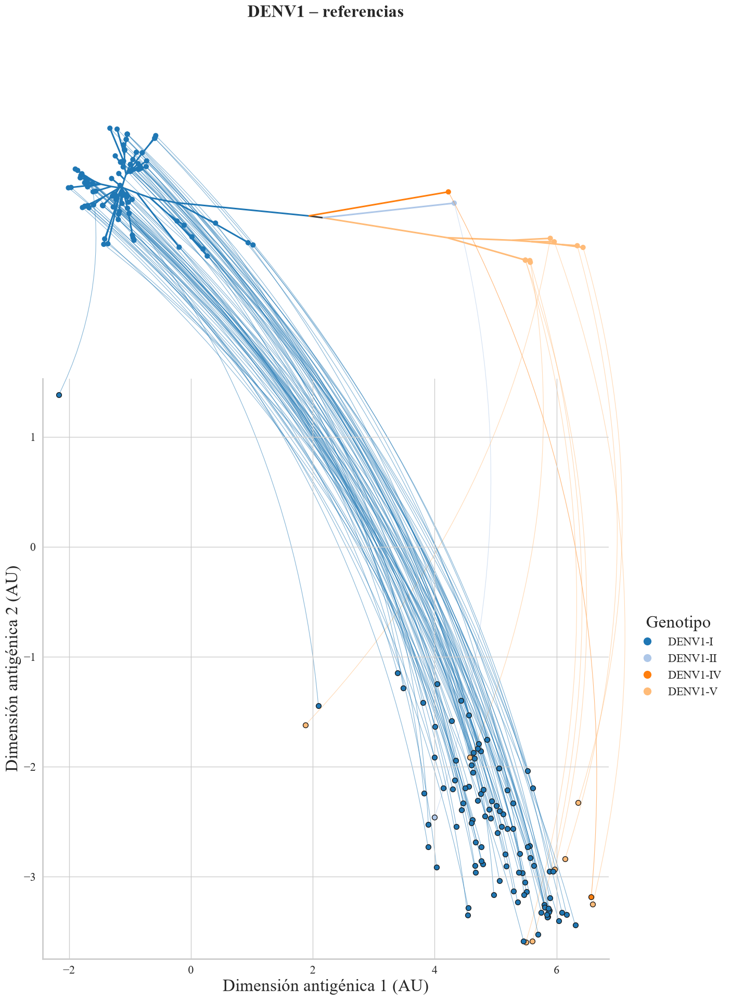

DENV2: 456 hojas | 96 con coordenadas
   árbol podado a 96 hojas
   con grupo asignado: 96 de 96 | 6 categorías


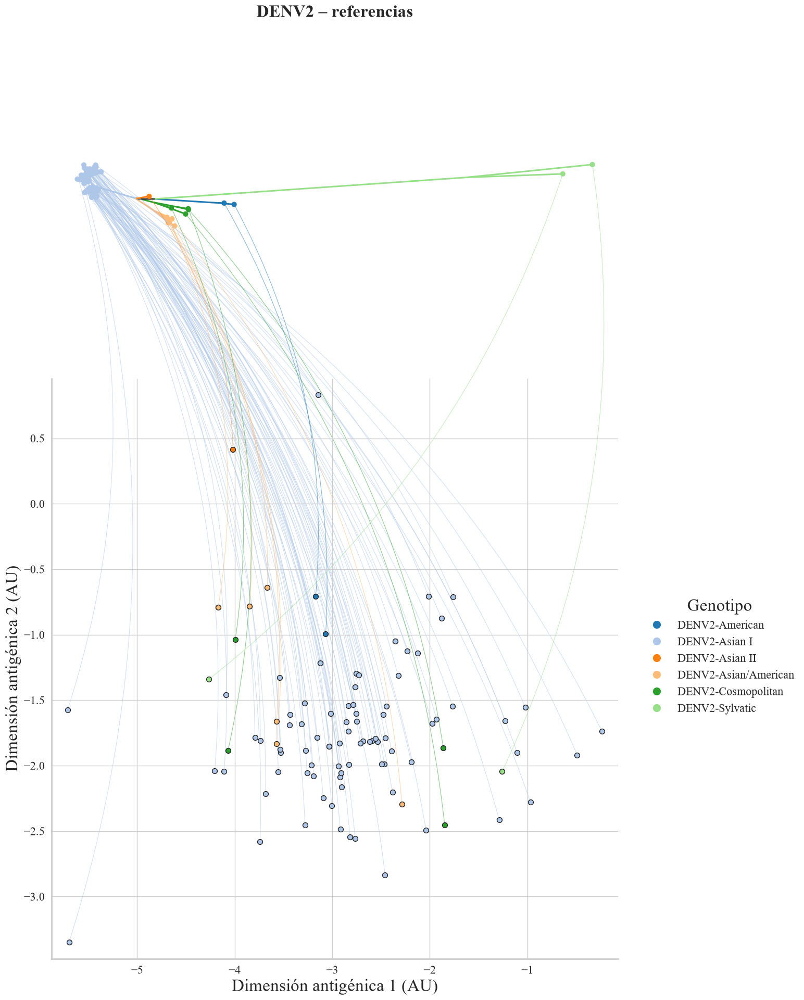

DENV3: 472 hojas | 102 con coordenadas
   árbol podado a 102 hojas
   con grupo asignado: 102 de 102 | 4 categorías


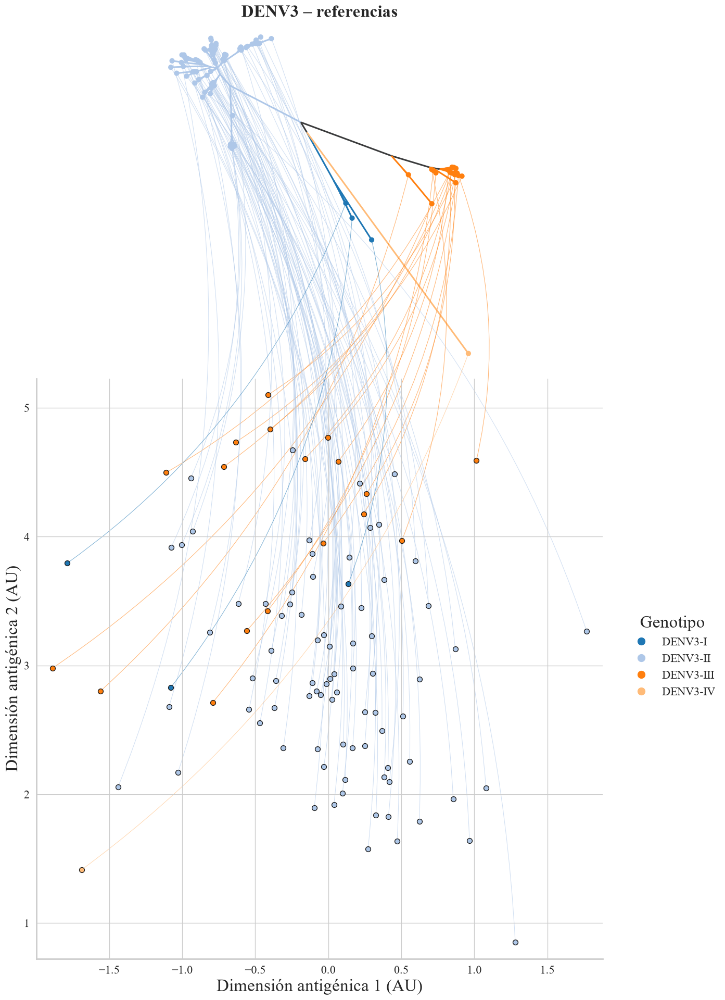

DENV4: 394 hojas | 101 con coordenadas
   árbol podado a 101 hojas
   con grupo asignado: 101 de 101 | 4 categorías


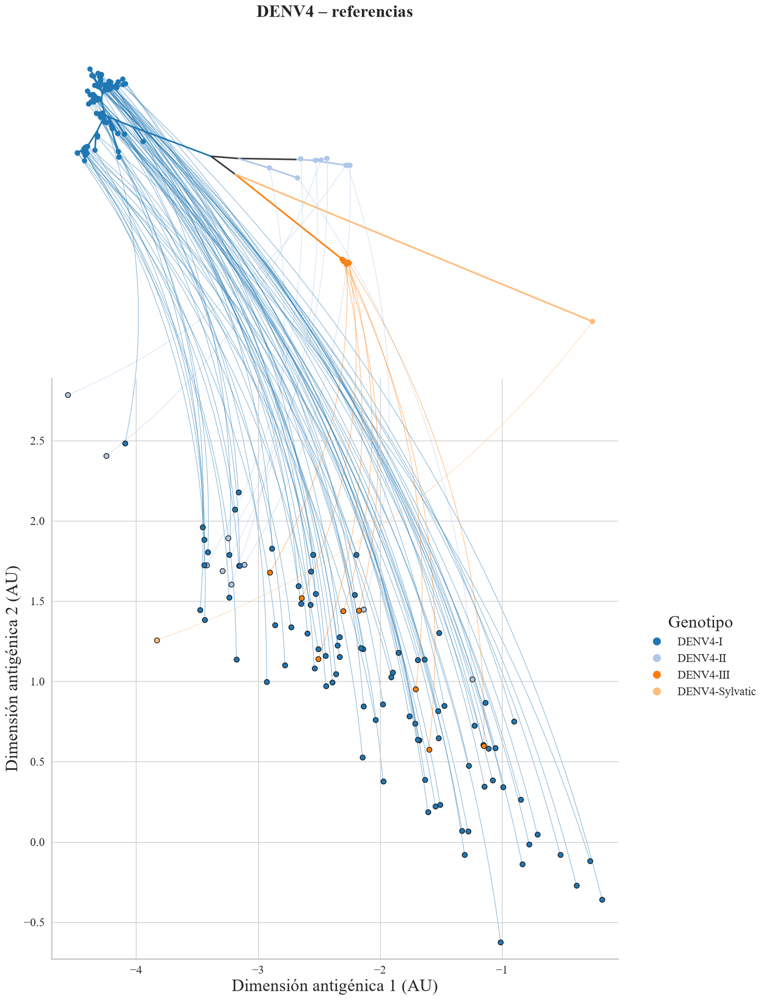

In [27]:
import io, re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D
from Bio import Phylo

sys.setrecursionlimit(10000)
GREY = "#999999"


# ───────────── 1) Leer el árbol MCC de BEAST (.tree, Nexus) ─────────────
def load_mcc(path):
    """Lee un árbol en Nexus (MCC de BEAST) o en Newick (.nwk, p. ej. ML).
    En Nexus aplica el bloque translate; en ambos casos elimina las anotaciones [&...]."""
    txt = open(path).read().replace("\r", "")
    trans = {}
    if "#nexus" in txt.lower():
        m = re.search(r"translate\s+(.*?);", txt, re.S | re.I)
        if m:
            for part in m.group(1).split(","):
                part = part.strip()
                if part:
                    k, v = part.split(None, 1)
                    trans[k] = v.strip().strip("'\"")
        tree_str = re.search(r"^\s*tree\s+[^=]+=\s*(.*?;)", txt, re.S | re.I | re.M).group(1)
    else:
        tree_str = txt.strip().split(";")[0] + ";"
    tree_str = re.sub(r"\[&[^\]]*\]", "", tree_str)
    tree = Phylo.read(io.StringIO(tree_str), "newick")
    for t in tree.get_terminals():
        t.name = trans.get(t.name, t.name).strip("'\"")
    return tree


def prune_to(tree, keep):
    """Deja solo las hojas cuyo nombre está en 'keep'; colapsa los nodos que quedan con un solo hijo
    sumando las longitudes de rama."""
    def rec(cl):
        if cl.is_terminal():
            return cl if cl.name in keep else None
        kids = [k for k in (rec(c) for c in cl.clades) if k is not None]
        if not kids:
            return None
        if len(kids) == 1:
            k = kids[0]; k.branch_length = (k.branch_length or 0.0) + (cl.branch_length or 0.0)
            return k
        cl.clades = kids
        return cl
    tree.root = rec(tree.root)
    return tree


def match_ids(tip_names, ids):
    """Empareja el nombre de cada hoja con el ID de la cepa (exacto, sin fecha tras '|', o sin distinguir mayúsculas)."""
    ids = set(ids); low = {i.lower(): i for i in ids}; out = {}
    for t in tip_names:
        for c in (t, t.split("|")[0], t.split("|")[0].replace("_", " ")):
            if c in ids:
                out[t] = c; break
            if c.lower() in low:
                out[t] = low[c.lower()]; break
    return out


# ───────────── 2) Distribución sin raíz (equal-angle) y datos por nodo ─────────────
def unrooted_layout(tree, rotate=0.2):
    """Coloca cada nodo del árbol en el plano. Devuelve:
       edges: lista de (clado_padre, clado_hijo, (x0,y0), (x1,y1)); pos: id(clado) -> (x,y)"""
    n_leaves = {}
    def count(cl):
        n_leaves[id(cl)] = 1 if cl.is_terminal() else sum(count(c) for c in cl.clades)
        return n_leaves[id(cl)]
    count(tree.root)

    pos, edges = {}, []
    def rec(cl, x, y, a0, a1):
        pos[id(cl)] = (x, y)
        ang = a0
        for ch in sorted(cl.clades, key=lambda c: -n_leaves[id(c)]):
            span = (a1 - a0) * n_leaves[id(ch)] / n_leaves[id(cl)]
            mid = ang + span / 2
            L = ch.branch_length or 0.0
            cx, cy = x + L * np.cos(mid), y + L * np.sin(mid)
            edges.append((cl, ch, (x, y), (cx, cy)))
            rec(ch, cx, cy, ang, ang + span)
            ang += span
    rec(tree.root, 0.0, 0.0, rotate, rotate + 2 * np.pi)
    return edges, pos


def leaf_sets(tree):
    """id(clado) -> conjunto de nombres de hojas descendientes."""
    out = {}
    def rec(cl):
        out[id(cl)] = {cl.name} if cl.is_terminal() else set().union(*(rec(c) for c in cl.clades))
        return out[id(cl)]
    rec(tree.root)
    return out


# ───────────── 3) Aristas del árbol sobre el espacio antigénico ─────────────
def phylo_segments(tree, xy, grp, gcol):
    """Cada nodo interno se ubica en el promedio de las coordenadas proyectadas de sus hojas
    descendientes; se traza padre -> hijo. xy y grp están indexados por nombre de hoja."""
    segs, cols = [], []
    def rec(cl):
        if cl.is_terminal():
            if cl.name in xy:
                return [xy[cl.name]], {grp.get(cl.name)}, xy[cl.name]
            return [], set(), None
        pts, gs, hijos = [], set(), []
        for ch in cl.clades:
            p, g, pos = rec(ch)
            pts += p; gs |= g
            hijos.append((pos, g))
        pos = np.mean(pts, axis=0) if pts else None
        for pos_h, g_h in hijos:
            if pos is not None and pos_h is not None:
                segs.append([pos, pos_h])
                cols.append(gcol.get(next(iter(g_h)), GREY) if len(g_h) == 1 else GREY)
        return pts, gs, pos
    rec(tree.root)
    return segs, cols


# ───────────── 4) Figura: árbol arriba, mapa de las proyectadas abajo ─────────────
def plot_tree_map(tree_file, proj, sero, groups, ref_xy=None, connect="tips",
                  out=None, rotate=0.2, group_title="Genotipo",
                  prune_unmatched=False, title=None):
    """
    tree_file : MCC de BEAST (.tree, Nexus) de ese serotipo
    proj      : DataFrame con columnas X, Y indexado por strainID (projected_coordinates[sero])
    groups    : Series strainID -> genotipo/clado (define los colores, como el clado en tu t-SNE)
    ref_xy    : DataFrame opcional con coord1, coord2 de las referencias (fondo gris claro)
    connect   : "tips"  -> línea curva de cada hoja del árbol a su punto en el mapa (como tu figura original)
                "phylo" -> además/en vez de eso, las aristas del árbol dibujadas sobre el mapa
                "both"
    """
    tree = load_mcc(tree_file)
    tips = [t.name for t in tree.get_terminals()]
    nm2id = match_ids(tips, proj.index)
    print(f"DENV{sero}: {len(tips)} hojas | {len(nm2id)} con coordenadas")
    if prune_unmatched and len(nm2id) < len(tips):       # árbol más grande que el mapa: dejar solo lo que tiene coordenadas
        tree = prune_to(tree, set(nm2id))
        tips = [t.name for t in tree.get_terminals()]
        print(f"   árbol podado a {len(tips)} hojas")
    if len(nm2id) < len(tips):
        print("   sin emparejar (ejemplos):", [t for t in tips if t not in nm2id][:5])

    xy = {t: proj.loc[i, ["X", "Y"]].values.astype(float) for t, i in nm2id.items()}
    groups = groups.dropna().astype(str)                 # acepta linajes numéricos o con vacíos
    grp = {t: groups.get(i) for t, i in nm2id.items()}
    print(f"   con grupo asignado: {sum(v is not None for v in grp.values())} de {len(grp)} | "
          f"{len(set(v for v in grp.values() if v is not None))} categorías")
    cats = sorted({g for g in grp.values() if isinstance(g, str)})
    pal = plt.get_cmap("tab20")
    gcol = {g: mcolors.to_hex(pal(i % 20)) for i, g in enumerate(cats)}
    color_of = lambda name: gcol.get(grp.get(name), "#CCCCCC")

    fig = plt.figure(figsize=(16, 20), facecolor="w")
    gs = gridspec.GridSpec(2, 1, height_ratios=[0.6, 1], hspace=0.02,
                           left=0.08, right=0.76, top=0.96, bottom=0.06)   # deja el 24% derecho para la leyenda
    ax_tree, ax_map = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    # --- árbol sin raíz, ramas coloreadas por grupo
    edges, pos = unrooted_layout(tree, rotate)
    leaves = leaf_sets(tree)

    def c_clade(cl):
        if cl.is_terminal():
            return color_of(cl.name)
        g = {grp.get(h) for h in leaves[id(cl)] if h in xy}
        return gcol.get(next(iter(g)), "#3A3B3C") if len(g) == 1 else "#3A3B3C"

    ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                           colors=[c_clade(e[1]) for e in edges], linewidths=2.2, zorder=10))
    leaf_xy = {t.name: pos[id(t)] for t in tree.get_terminals()}
    ax_tree.scatter([p[0] for p in leaf_xy.values()], [p[1] for p in leaf_xy.values()],
                    c=[color_of(n) for n in leaf_xy], s=40, zorder=20)
    ax_tree.autoscale_view(); ax_tree.set_aspect("equal", adjustable="datalim")
    for sp in ax_tree.spines.values(): sp.set_visible(False)
    ax_tree.set_xticks([]); ax_tree.set_yticks([])

    # --- mapa antigénico de las cepas proyectadas
    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=18, c="#e3e3e3", zorder=0)
    if connect in ("phylo", "both"):
        segs, cols = phylo_segments(tree, xy, grp, gcol)
        ax_map.add_collection(LineCollection(segs, colors=cols, linewidths=0.8, alpha=0.5, zorder=1))
    for name, p in xy.items():
        ax_map.scatter(*p, c=color_of(name), edgecolor="k", s=50, alpha=1, zorder=3)

    # --- conexión hoja del árbol -> punto en el mapa (mismo color), como en tu t-SNE
    if connect in ("tips", "both"):
        for name, p in xy.items():
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(p), coordsA=ax_map.transData,
                xyB=leaf_xy[name], coordsB=ax_tree.transData,
                linestyle="-", color=color_of(name), linewidth=0.8, alpha=0.55,
                connectionstyle="arc3,rad=0.15", zorder=0))

    ax_map.margins(x=0.03, y=0.03)
    ax_map.set_xlabel("Dimensión antigénica 1 (AU)", fontsize=24)
    ax_map.set_ylabel("Dimensión antigénica 2 (AU)", fontsize=24)
    ax_map.tick_params(axis="both", labelsize=16)
    for sp in ("right", "top"): ax_map.spines[sp].set_visible(False)
    for sp in ax_map.spines.values(): sp.set_linewidth(2)

    handles = [Line2D([0], [0], marker="o", color="w", label=g, markerfacecolor=gcol[g],
                      markersize=8) for g in cats if g in set(grp.values())]
    fig.legend(handles=handles, title=group_title, loc="center left",
               bbox_to_anchor=(0.78, 0.35), frameon=False,
               fontsize=16, title_fontsize=24, markerscale=1.5)      # en coordenadas de la figura
    ax_tree.set_title(title or f"DENV{sero}", fontsize=24, fontweight="bold")
    if out:
        plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()


TREE_EXP = "../resources/experimental_data/tree/E_DENV{}_tree.nwk"
INFO_FILE = "../resources/experimental_data/information.viruses.csv"
ag = mapa_ag[mapa_ag["type"] == "AG"].drop_duplicates("strainID").set_index("strainID")
ref_proj = ag.rename(columns={"coord1": "X", "coord2": "Y"})[["X", "Y"]]     # coordenadas originales del mapa
geno = (pd.read_csv(INFO_FILE).drop_duplicates("unified.sequence.names")
        .set_index("unified.sequence.names")["genotype"])

for sero in [1, 2, 3, 4]:
    sub = ref_proj[ref_proj.index.str.startswith(f"DENV{sero}/")]
    plot_tree_map(TREE_EXP.format(sero), sub, sero, groups=geno,
                  ref_xy=ag[ag["sero"] == str(sero)],          # fondo gris: el resto de antígenos del serotipo
                  group_title="Genotipo", prune_unmatched=True,
                  title=f"DENV{sero} – referencias",
                  out=f"../figures/arbol_mapa_ref_DENV{sero}.png")